# Colab experiment
Run from the top in Google Colab. Choose the required runtime first. If dependency installation asks for a runtime restart, restart and run from the top again. Set RESUME_RUN_ID only for an explicitly verified compatible checkpoint. Use RECOVER_RUN_ID to deliver staged results without rerunning compute. For a shared folder, add its shortcut in My Drive or set PROJECT_PATH_OVERRIDE to the actual mounted folder path. Put credentials in Colab Secrets; never paste them into this notebook.


In [1]:
import json, sys, subprocess, importlib.metadata, time, uuid
from pathlib import Path
CONFIG = json.loads('{"budget":{"estimated_hours":0.15,"max_hours":2.0},"confirmed":true,"context":{"dataset_id":"rdd2020_datasprint_2_0","dataset_revision":"2026-11-23","evaluation_config_hash":"full_21041_eda","evaluator_id":"eda_only","evaluator_revision":"v1","n_samples":21041,"split_hash":"train14691_val2150_test4200","split_id":"official_train_val_test"},"dependency_check":"required","drive_folder_id":"1n8ddoVvmlpff1ScGLi_WPw-pPBe_AyC1","drive_relative_path":"DataSprint_2.0_Road_Damage","experiment":{"max_grid_images_per_class":6,"quality_sample_per_split":1000,"seed":42},"experiment_name":"datasprint2_full_dataset_eda_v1","gpu_required":false,"metric_context":{"background_only_pct_val":{"higher_is_better":false,"split":"val","unit":"percent"},"class_imbalance_ratio_train":{"higher_is_better":false,"split":"train","unit":"ratio"},"cross_split_exact_dupes":{"higher_is_better":false,"split":"all","unit":"count"},"test_images":{"higher_is_better":true,"split":"test","unit":"count"},"test_low_bpp_p05":{"higher_is_better":true,"split":"test","unit":"bytes_per_px"},"train_boxes":{"higher_is_better":true,"split":"train","unit":"count"},"train_images":{"higher_is_better":true,"split":"train","unit":"count"},"val_boxes":{"higher_is_better":true,"split":"val","unit":"count"},"val_images":{"higher_is_better":true,"split":"val","unit":"count"},"val_low_bpp_p05":{"higher_is_better":true,"split":"val","unit":"bytes_per_px"}},"min_free_disk_gib":10,"min_gpu_memory_gib":0,"packages":[],"project_id":"datasprint-2-0-road-damage","schema_version":"colab-builder-config/1","source_fingerprints":{"builder_sha256":"40efd2603d219b5ffce5bca7f5149ed20644fb0e49db68cc529b6b4f86a998a0","runtime_sha256":"e30c67b27342488b5304b3b938070e2fbe06c8a8cdcc3064cc645e732c2f906c","task_sha256":"a5b51f8da413668fb6c496242995515115890c7260082353df5dce102fb4eebf"},"workload":"eda"}')
RESUME_RUN_ID = ''  # Set an existing run ID only when resuming.
RECOVER_RUN_ID = ''  # Deliver saved results only; does not rerun the task.
PROJECT_PATH_OVERRIDE = ''  # Optional path inside /content/drive.
START_NEW_RUN = False  # Set True for a fresh independent attempt.
if not RECOVER_RUN_ID and CONFIG.get('python_min') and sys.version_info[:2] < tuple(map(int, CONFIG['python_min'].split('.'))):
    raise RuntimeError('Python version below project requirement; choose a compatible Colab runtime')
if not RECOVER_RUN_ID and CONFIG.get('python_max_exclusive') and sys.version_info[:2] >= tuple(map(int, CONFIG['python_max_exclusive'].split('.'))):
    raise RuntimeError('Python version outside project compatibility range')
if RESUME_RUN_ID and RECOVER_RUN_ID:
    raise ValueError('Select recovery or checkpoint resumption, not both')
if RESUME_RUN_ID or RECOVER_RUN_ID:
    RUN_ID = RESUME_RUN_ID or RECOVER_RUN_ID
elif START_NEW_RUN or 'RUN_ID' not in globals() or globals().get('RUN_PROJECT_ID') != CONFIG['project_id']:
    RUN_ID = str(uuid.uuid4())
RUN_PROJECT_ID = CONFIG['project_id']
print('Run ID:', RUN_ID)
import importlib.util
RUNTIME_SOURCE = '"""Standard-library logging/recovery. No network calls or ML dependencies.\n\nAuditing third-party requirement markers uses the installed packaging parser.\nStandard-library-only EDA and event recovery do not require that package.\n\nLocal locks/CAS do not provide distributed locking on a mounted Google Drive.\nSerialize remote writers and reconcile destination markers before retrying writes.\n"""\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport os\nimport re\nimport tempfile\nimport uuid\nimport importlib.metadata\nimport subprocess\nimport sys\nfrom contextlib import contextmanager\nfrom datetime import datetime, timezone\nfrom pathlib import Path\n\nSCHEMA_VERSION = 2\n_ID = re.compile(r"[A-Za-z0-9][A-Za-z0-9_-]{0,95}\\Z")\n_SECRET = re.compile(r"(?:^|_)(?:api_key|access_token|refresh_token|hf_token|password|secret|authorization|cookie|credentials|private_key|secret_access_key|access_key_id)$")\nDEFAULT_CONTEXT_KEYS = (\n    "dataset_id", "dataset_revision", "split_id", "split_hash",\n    "evaluator_id", "evaluator_revision", "evaluation_config_hash", "n_samples",\n)\n\n\ndef utc_now():\n    return datetime.now(timezone.utc).isoformat(timespec="microseconds")\n\n\ndef check_json(value, path="root"):\n    """Reject non-JSON objects, non-finite values, and credential-bearing keys."""\n    if value is None or isinstance(value, (str, bool, int)):\n        return\n    if isinstance(value, float):\n        if not math.isfinite(value):\n            raise ValueError(f"Non-finite number at {path}")\n        return\n    if isinstance(value, list):\n        for i, child in enumerate(value):\n            check_json(child, f"{path}[{i}]")\n        return\n    if isinstance(value, dict):\n        for key, child in value.items():\n            if not isinstance(key, str):\n                raise TypeError("JSON object keys must be strings")\n            snake = re.sub(r"([a-z0-9])([A-Z])", r"\\1_\\2", key)\n            normalized = re.sub(r"[^a-z0-9]+", "_", snake.lower()).strip("_")\n            if _SECRET.search(normalized) or normalized in {"token", "apikey"}:\n                raise ValueError("Credential-bearing field rejected; use Colab Secrets")\n            check_json(child, f"{path}.{key}")\n        return\n    raise TypeError(f"Unsupported JSON value at {path}; convert explicitly")\n\n\ndef canonical(value):\n    check_json(value)\n    return json.dumps(value, sort_keys=True, ensure_ascii=False,\n                      separators=(",", ":"), allow_nan=False).encode("utf-8")\n\n\ndef digest(value):\n    return hashlib.sha256(canonical(value)).hexdigest()\n\n\ndef file_digest(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef strict_loads(text):\n    # Reject NaN/Infinity rather than silently accepting JavaScript extensions.\n    def reject(_):\n        raise ValueError("Invalid JSON numeric constant")\n    def unique_pairs(pairs):\n        result = {}\n        for key, value in pairs:\n            if key in result:\n                raise ValueError("Duplicate JSON object key")\n            result[key] = value\n        return result\n    def finite_float(raw):\n        number = float(raw)\n        if not math.isfinite(number):\n            raise ValueError("Invalid JSON numeric constant")\n        return number\n    return json.loads(text, parse_constant=reject, object_pairs_hook=unique_pairs, parse_float=finite_float)\n\n\ndef read_json(path):\n    return strict_loads(Path(path).read_text(encoding="utf-8"))\n\n\ndef component(value):\n    if not isinstance(value, str) or not _ID.fullmatch(value):\n        raise ValueError("Use a nonempty, safe ID (letters, digits, hyphen, underscore)")\n    return value\n\n\ndef within(root, relative):\n    root = Path(root).resolve()\n    rel = Path(relative)\n    if rel.is_absolute() or ".." in rel.parts:\n        raise ValueError("Expected a project-relative path")\n    target = (root / rel).resolve()\n    if target == root or root not in target.parents:\n        raise ValueError("Path escapes project or names its root")\n    return target\n\n\ndef resolve_project_root(mount_root, relative_path, project_id, *, override=\'\', folder_id=None):\n    """Resolve an explicit mounted path and verify identity before ANY write.\n\n    Shared-folder visibility is not inferred from connector access. An override\n    must remain inside the mount and point at the verified project registry.\n    """\n    mount = Path(mount_root).resolve()\n    if override:\n        target = Path(override)\n        if not target.is_absolute():\n            target = mount / target\n        target = target.resolve()\n        if mount not in target.parents:\n            raise ValueError(\'Project override must be inside the mounted Drive\')\n    else:\n        target = within(mount / \'MyDrive\', relative_path)\n    state_path = target / \'05_reports/autopilot/project_state.json\'\n    if not state_path.is_file():\n        raise FileNotFoundError(\'Project is not visible in mounted Drive. Add its shortcut to My Drive, \'\n                                \'or set PROJECT_PATH_OVERRIDE to its mounted path. Mount an account \'\n                                \'that can access the folder. No replacement project was created.\')\n    state = read_json(state_path)\n    if state.get(\'schema_version\') != SCHEMA_VERSION or state.get(\'project_id\') != project_id:\n        raise ValueError(\'Mounted project identity/schema mismatch\')\n    if folder_id and state.get(\'registry\', {}).get(\'root_folder\', {}).get(\'id\') != folder_id:\n        raise ValueError(\'Mounted Drive folder ID mismatch\')\n    return target\n\n\ndef dependency_report(pins, *, policy=\'required\', run=subprocess.run,\n                      requires=importlib.metadata.requires):\n    """Inspect pip check, blocking workload dependency conflicts.\n\n    Unrelated preinstalled conflicts are surfaced separately; unknown checker\n    failures still stop execution. No environment-wide repair or uninstall.\n    """\n    if policy not in {\'required\', \'all\'}:\n        raise ValueError(\'Unknown dependency policy\')\n    normalize = lambda name: re.sub(r\'[-_.]+\', \'-\', name.lower())\n    roots = {normalize(pin.split(\'==\', 1)[0]) for pin in pins}\n    required = set(roots)\n    requested_extras = {name: set() for name in roots}\n    processed = {}\n    queue = list(required)\n    while queue:\n        name = queue.pop()\n        active_extras = requested_extras[name]\n        if name in processed and processed[name] == active_extras:\n            continue\n        processed[name] = set(active_extras)\n        try:\n            dependencies = requires(name) or []\n        except importlib.metadata.PackageNotFoundError:\n            if name in roots:\n                raise RuntimeError(\'A required package is missing\') from None\n            continue  # Optional/conditional requirement; pip check judges runtime applicability.\n        for requirement in dependencies:\n            try:\n                from packaging.requirements import Requirement\n            except ImportError:\n                raise RuntimeError(\'Requirement metadata needs the packaging parser; include a compatible packaging pin\') from None\n            try:\n                parsed = Requirement(requirement)\n                if parsed.marker and not any(parsed.marker.evaluate({\'extra\': extra})\n                                             for extra in {\'\'} | active_extras):\n                    continue\n            except (ValueError, KeyError):\n                raise RuntimeError(\'Cannot interpret a required dependency marker\') from None\n            child = normalize(parsed.name)\n            extras = {normalize(extra) for extra in parsed.extras}\n            if child not in requested_extras or not extras <= requested_extras[child]:\n                requested_extras.setdefault(child, set()).update(extras)\n                required.add(child)\n                queue.append(child)\n    checked = run([sys.executable, \'-m\', \'pip\', \'check\'], capture_output=True, text=True)\n    if checked.returncode == 0:\n        return {\'status\': \'clean\', \'unrelated_conflicts\': 0, \'required_packages\': sorted(required)}\n    conflicts = []\n    for line in checked.stdout.splitlines():\n        match = re.match(r\'^([A-Za-z0-9_.-]+)\\s+\\S+\\s+(?:requires|has requirement)\\s+([A-Za-z0-9_.-]+)\', line)\n        if not match:\n            raise RuntimeError(\'Dependency checker failed or returned an unrecognized conflict\')\n        conflicts.append((normalize(match[1]), normalize(match[2])))\n    if not conflicts or checked.stderr.strip():\n        raise RuntimeError(\'Dependency checker did not produce a valid report\')\n    # Only requirements OF the workload closure constrain this run. An unrelated\n    # reverse dependent (for example an unused app constraining numpy) does not.\n    if policy == \'all\' or any(a in required for a, b in conflicts):\n        raise RuntimeError(\'Required dependency conflict; diagnose before running this workload\')\n    return {\'status\': \'unrelated_conflicts\', \'unrelated_conflicts\': len(conflicts),\n            \'required_packages\': sorted(required)}\n\n\n@contextmanager\ndef local_lock(path):\n    """Fail closed on contention. Never auto-delete another writer\'s lock."""\n    lock = Path(str(path) + ".lock")\n    lock.parent.mkdir(parents=True, exist_ok=True)\n    fd = os.open(str(lock), os.O_CREAT | os.O_EXCL | os.O_WRONLY, 0o600)\n    try:\n        os.write(fd, str(os.getpid()).encode("ascii"))\n        os.close(fd)\n        fd = None\n        yield\n    finally:\n        if fd is not None:\n            os.close(fd)\n        lock.unlink()\n\n\ndef atomic_json(path, value, *, expected=None, absent=False):\n    """Atomic same-directory replace plus a local cooperative lock and SHA CAS."""\n    path = Path(path)\n    payload = canonical(value)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with local_lock(path):\n        if absent and path.exists():\n            raise FileExistsError(str(path))\n        if expected is not None and (not path.exists() or file_digest(path) != expected):\n            raise RuntimeError("State changed; reload and reconcile")\n        fd, temporary = tempfile.mkstemp(prefix=".pending-", dir=path.parent)\n        try:\n            with os.fdopen(fd, "wb") as out:\n                out.write(payload)\n                out.flush()\n                os.fsync(out.fileno())\n            os.replace(temporary, path)\n        finally:\n            if os.path.exists(temporary):\n                os.unlink(temporary)\n    # Readback checks local bytes only; it cannot prove Drive server durability.\n    if path.read_bytes() != payload:\n        raise IOError("JSON write readback mismatch")\n    return path\n\n\ndef _numeric(value):\n    return (not isinstance(value, bool) and\n            (isinstance(value, int) or isinstance(value, float) and math.isfinite(value)))\n\n\ndef validate_metrics(metrics):\n    if not isinstance(metrics, dict):\n        raise TypeError("metrics must be a JSON object")\n    for name, value in metrics.items():\n        if not isinstance(name, str) or not name or not _numeric(value):\n            raise ValueError("Metric names must be nonempty strings and values finite numbers")\n\n\nclass LogDeliveryError(OSError):\n    """The log is staged locally but its project destination was not verified."""\n    def __init__(self, spool_path, error_category):\n        self.spool_path = Path(spool_path)\n        self.error_category = error_category\n        super().__init__(f"Log delivery pending ({error_category}); recover from {self.spool_path}")\n\n\ndef _write_event(path, record):\n    try:\n        atomic_json(path, record, absent=True)\n    except FileExistsError:\n        if not path.is_file():\n            raise\n        prior = read_json(path)\n        body = {k: v for k, v in prior.items() if k not in {"timestamp_utc", "payload_digest"}}\n        expected = record["payload_digest"]\n        if prior.get("payload_digest") != expected or digest(body) != expected:\n            raise FileExistsError("Event ID already contains different data; choose a revision ID") from None\n    return path\n\n\ndef validate_context(context, metric_context):\n    if not isinstance(context,dict) or not isinstance(metric_context,dict):\n        raise ValueError(\'Evaluation context and metric_context must be objects\')\n    if any(not isinstance(key,str) or not key.strip() or not isinstance(value,dict)\n           for key,value in metric_context.items()):\n        raise ValueError(\'Each metric context must be a named object\')\n    check_json(context)\n    check_json(metric_context)\n\n\ndef validate_event(record, *, run_id=None, project_id=None):\n    """Validate a saved event before sync or recovery; never execute its source."""\n    check_json(record)\n    if not isinstance(record, dict) or record.get(\'schema_version\') != SCHEMA_VERSION:\n        raise ValueError(\'Unsupported event schema\')\n    component(record.get(\'run_id\'))\n    component(record.get(\'event_id\'))\n    if run_id and record[\'run_id\'] != run_id:\n        raise ValueError(\'Event run identity mismatch\')\n    if not isinstance(record.get(\'config\'), dict):\n        raise ValueError(\'Event configuration is missing\')\n    if project_id and record[\'config\'].get(\'project_id\') != project_id:\n        raise ValueError(\'Event project identity mismatch\')\n    if record.get(\'status\') not in {\'completed\', \'partial\', \'failed\', \'interrupted\'}:\n        raise ValueError(\'Invalid event status\')\n    validate_context(record.get(\'context\', {}), record.get(\'metric_context\', {}))\n    validate_metrics(record.get(\'metrics\'))\n    if record[\'status\'] == \'completed\' and not record[\'metrics\']:\n        raise ValueError(\'Completed event lacks metrics\')\n    body = {k: v for k, v in record.items() if k not in {\'timestamp_utc\', \'payload_digest\'}}\n    if digest(body) != record.get(\'payload_digest\'):\n        raise ValueError(\'Event payload checksum mismatch\')\n    return record\n\n\ndef copy_immutable_file(source, destination, expected_sha256, *, max_bytes=16 * 1024 * 1024):\n    """Recover bounded task artifacts; refuse oversized files and replacements."""\n    source, destination = Path(source), Path(destination)\n    if source.stat().st_size > max_bytes:\n        raise ValueError(\'Recovery artifact is too large or has a mismatched checksum\')\n    with source.open(\'rb\') as stream:\n        payload = stream.read(max_bytes + 1)\n    if len(payload) > max_bytes or hashlib.sha256(payload).hexdigest() != expected_sha256:\n        raise ValueError(\'Recovery artifact is too large or has a mismatched checksum\')\n    destination.parent.mkdir(parents=True, exist_ok=True)\n    with local_lock(destination):\n        if destination.exists():\n            if file_digest(destination) != expected_sha256:\n                raise FileExistsError(\'Recovery destination contains different content\')\n            return destination\n        fd, temporary = tempfile.mkstemp(prefix=\'.recovery-\', dir=destination.parent)\n        try:\n            with os.fdopen(fd, \'wb\') as stream:\n                stream.write(payload)\n                stream.flush()\n                os.fsync(stream.fileno())\n            os.replace(temporary, destination)\n        finally:\n            if os.path.exists(temporary):\n                os.unlink(temporary)\n    if file_digest(destination) != expected_sha256:\n        raise IOError(\'Recovery artifact readback mismatch\')\n    return destination\n\n\ndef recover_spooled_events(project_root, spool_root, run_id, *, project_id):\n    """Deliver original staged events and bounded artifacts WITHOUT recompute."""\n    run_id = component(run_id)\n    state = read_json(within(project_root, \'05_reports/autopilot/project_state.json\'))\n    if state.get(\'schema_version\') != SCHEMA_VERSION or state.get(\'project_id\') != project_id:\n        raise ValueError(\'Recovery project mismatch\')\n    events = within(spool_root, f\'03_results/runs/{run_id}/events\')\n    delivered = []\n    for source in sorted(events.glob(\'*.json\')):\n        source = within(spool_root, f\'03_results/runs/{run_id}/events/{source.name}\')\n        record = validate_event(read_json(source), run_id=run_id, project_id=project_id)\n        if source.stem != record[\'event_id\']:\n            raise ValueError(\'Event path identity mismatch\')\n        artifacts = record.get(\'artifacts\', {}).get(\'files\', {})\n        if not isinstance(artifacts, dict):\n            raise ValueError(\'Invalid artifact manifest\')\n        for relative, sha256 in artifacts.items():\n            copy_immutable_file(within(spool_root, relative), within(project_root, relative), sha256)\n        destination = within(project_root, f\'03_results/runs/{run_id}/events/{source.name}\')\n        _write_event(destination, record)\n        observed = validate_event(read_json(destination), run_id=run_id, project_id=project_id)\n        if observed[\'payload_digest\'] != record[\'payload_digest\']:\n            raise IOError(\'Recovered event readback mismatch\')\n        delivered.append({\'event_id\': record[\'event_id\'], \'status\': record[\'status\']})\n    return delivered\n\n\ndef log_experiment(project_root, exp_id, metrics, *, run_id=None, event_id="final",\n                   status="completed", model_name=None, config=None, context=None,\n                   metric_context=None, artifacts=None, notes="", errors=None,\n                   spool_root=None):\n    """Write an immutable run event. Retry with the SAME run_id/event_id.\n\n    A different payload at an existing ID raises; log corrections under a new\n    event_id. Returned files contain JSON primitives only. No secret values print.\n    """\n    run_id = component(run_id or str(uuid.uuid4()))\n    event_id = component(event_id)\n    if status not in {"completed", "partial", "failed", "interrupted"}:\n        raise ValueError("Unknown run status")\n    if config is not None and not isinstance(config,dict):\n        raise ValueError("Experiment config must be an object")\n    validate_context({} if context is None else context, {} if metric_context is None else metric_context)\n    validate_metrics(metrics)\n    if status == "completed" and not metrics:\n        raise ValueError("Completed runs need observed metrics")\n    if artifacts is not None and not isinstance(artifacts, dict):\n        raise ValueError(\'Artifacts must be an object\')\n    files = (artifacts or {}).get(\'files\', {})\n    if not isinstance(files, dict) or any(not isinstance(path, str) or not isinstance(sha, str)\n            or not re.fullmatch(\'[0-9a-f]{64}\', sha) for path, sha in files.items()):\n        raise ValueError(\'Artifact files need relative paths and SHA-256 strings\')\n    # Invalid local exports are task/export failures, not completed results to\n    # recover. Validate before staging an immutable terminal event. Delivery\n    # still copies/checks again to detect a subsequent source change.\n    if spool_root is not None:\n        for relative, expected_hash in files.items():\n            source = within(spool_root, relative)\n            if not source.is_file() or source.stat().st_size > 16 * 1024 * 1024 or file_digest(source) != expected_hash:\n                raise ValueError(\'Staged task artifact is missing, oversized, or has a mismatched checksum\')\n    body = {\n        "schema_version": SCHEMA_VERSION, "run_id": run_id, "event_id": event_id,\n        "exp_id": exp_id, "status": status, "model_name": model_name,\n        "metrics": metrics, "config": config or {}, "context": context or {},\n        "metric_context": metric_context or {}, "artifacts": artifacts or {},\n        "notes": notes, "errors": errors or [],\n    }\n    payload_digest = digest(body)\n    path = within(project_root, f"03_results/runs/{run_id}/events/{event_id}.json")\n    record = {**body, "timestamp_utc": utc_now(), "payload_digest": payload_digest}\n    # Reuse the immutable destination timestamp when the same event is restaged\n    # into a new spool. A mount/read failure must not prevent local staging.\n    try:\n        previous = validate_event(read_json(path), run_id=run_id)\n    except (OSError, ValueError, TypeError):\n        previous = None\n    if previous is not None and previous[\'payload_digest\'] == payload_digest:\n        record = previous\n    spool_path = None\n    if spool_root is not None:\n        if Path(spool_root).resolve() == Path(project_root).resolve():\n            raise ValueError("Use separate local spool storage")\n        spool_path = within(spool_root, f"03_results/runs/{run_id}/events/{event_id}.json")\n        _write_event(spool_path, record)\n        # Deliver the original staged bytes/UTC time after an uncertain retry.\n        record = read_json(spool_path)\n    try:\n        for relative, expected_hash in record[\'artifacts\'].get(\'files\', {}).items():\n            destination = within(project_root, relative)\n            if spool_root is not None:\n                copy_immutable_file(within(spool_root, relative), destination, expected_hash)\n            elif not destination.is_file() or file_digest(destination) != expected_hash:\n                raise ValueError(\'Task artifact could not be verified\')\n        return _write_event(path, record)\n    except (OSError, ValueError) as error:\n        if spool_path is not None:\n            raise LogDeliveryError(spool_path, type(error).__name__) from None\n        raise\n\n\ndef save_checkpoint_manifest(project_root, run_id, checkpoint_id, config, files):\n    """Call only AFTER model/optimizer/RNG artifacts have been fully written."""\n    run_id, checkpoint_id = component(run_id), component(checkpoint_id)\n    if not files or not isinstance(files, list):\n        raise ValueError("List at least one finalized checkpoint artifact")\n    hashes = {}\n    for relative in files:\n        target = within(project_root, relative)\n        if not target.is_file():\n            raise FileNotFoundError(str(target))\n        hashes[Path(relative).as_posix()] = file_digest(target)\n    payload = {"schema_version": SCHEMA_VERSION, "run_id": run_id,\n               "checkpoint_id": checkpoint_id, "config_digest": digest(config),\n               "files": hashes, "complete": True}\n    path = within(project_root, f"03_results/runs/{run_id}/checkpoints/{checkpoint_id}.json")\n    try:\n        return atomic_json(path, payload, absent=True)\n    except FileExistsError:\n        if read_json(path) != payload:\n            raise FileExistsError("Checkpoint manifest is immutable") from None\n        return path\n\n\ndef verify_checkpoint(project_root, manifest_path, config, *, run_id):\n    manifest = read_json(manifest_path)\n    if (manifest.get("schema_version") != SCHEMA_VERSION or manifest.get("complete") is not True\n            or manifest.get("run_id") != component(run_id)\n            or manifest.get("config_digest") != digest(config) or not manifest.get("files")):\n        raise ValueError("Checkpoint context/run mismatch or incomplete manifest")\n    for relative, expected in manifest["files"].items():\n        if file_digest(within(project_root, relative)) != expected:\n            raise ValueError("Checkpoint artifact checksum mismatch")\n    return manifest\n\n\ndef seed_everything(seed=42, *, deterministic=True):\n    """Lock Python and any already-loaded NumPy/PyTorch RNGs; return JSON receipt."""\n    if isinstance(seed, bool) or not isinstance(seed, int) or seed < 0:\n        raise ValueError("seed must be a non-negative integer")\n    import random\n    os.environ["PYTHONHASHSEED"] = str(seed)\n    random.seed(seed)\n    seeded = ["python_random"]\n    np_mod = sys.modules.get("numpy")\n    if np_mod is not None and hasattr(np_mod, "random"):\n        np_mod.random.seed(seed)\n        seeded.append("numpy")\n    torch_mod = sys.modules.get("torch")\n    if torch_mod is not None and hasattr(torch_mod, "manual_seed"):\n        torch_mod.manual_seed(seed)\n        seeded.append("torch_cpu")\n        if hasattr(torch_mod, "cuda") and torch_mod.cuda.is_available():\n            torch_mod.cuda.manual_seed_all(seed)\n            seeded.append("torch_cuda")\n        if hasattr(torch_mod, "backends") and hasattr(torch_mod.backends, "cudnn"):\n            torch_mod.backends.cudnn.deterministic = bool(deterministic)\n            torch_mod.backends.cudnn.benchmark = not bool(deterministic)\n    return {"seed": seed, "deterministic": bool(deterministic), "seeded_modules": seeded}\n\n\ndef stage_to_local_cache(project_root, relative_path, cache_root="/content/autopilot_cache", *, expected_sha256=None):\n    """Stage a Drive file to fast local Colab disk with SHA-256 verification."""\n    source = within(project_root, relative_path)\n    if not source.is_file():\n        raise FileNotFoundError(str(source))\n    target = within(cache_root, relative_path)\n    source_size = source.stat().st_size\n    if target.is_file() and target.stat().st_size == source_size:\n        cached_sha = file_digest(target)\n        if expected_sha256 is None or cached_sha == expected_sha256:\n            if expected_sha256 is not None or cached_sha == file_digest(source):\n                return {"local_path": str(target), "sha256": cached_sha,\n                        "size_bytes": source_size, "cache_hit": True}\n    source_sha = file_digest(source)\n    if expected_sha256 is not None and source_sha != expected_sha256:\n        raise ValueError("Source file SHA-256 mismatch before local caching")\n    target.parent.mkdir(parents=True, exist_ok=True)\n    fd, temporary = tempfile.mkstemp(prefix=".cache-", dir=target.parent)\n    try:\n        with os.fdopen(fd, "wb") as out, source.open("rb") as inp:\n            for block in iter(lambda: inp.read(1024 * 1024), b""):\n                out.write(block)\n            out.flush()\n            os.fsync(out.fileno())\n        os.replace(temporary, target)\n    finally:\n        if os.path.exists(temporary):\n            os.unlink(temporary)\n    if file_digest(target) != source_sha:\n        raise IOError("Local cache readback checksum mismatch")\n    return {"local_path": str(target), "sha256": source_sha,\n            "size_bytes": source_size, "cache_hit": False}\n\n\ndef collect_colab_telemetry(elapsed_seconds, *, burn_rate_cu_per_hour=None):\n    """Collect JSON-safe Colab compute telemetry (elapsed, peak VRAM, estimated CUs)."""\n    if isinstance(elapsed_seconds, bool) or not _numeric(elapsed_seconds) or elapsed_seconds < 0:\n        raise ValueError("elapsed_seconds must be a non-negative finite number")\n    telemetry = {"elapsed_seconds": float(elapsed_seconds)}\n    if burn_rate_cu_per_hour is not None:\n        if isinstance(burn_rate_cu_per_hour, bool) or not _numeric(burn_rate_cu_per_hour) or burn_rate_cu_per_hour < 0:\n            raise ValueError("burn_rate_cu_per_hour must be a non-negative finite number")\n        telemetry["burn_rate_cu_per_hour"] = float(burn_rate_cu_per_hour)\n        telemetry["estimated_compute_units"] = round((float(elapsed_seconds) / 3600.0) * float(burn_rate_cu_per_hour), 4)\n    torch_mod = sys.modules.get("torch")\n    if torch_mod is not None and hasattr(torch_mod, "cuda") and torch_mod.cuda.is_available():\n        try:\n            telemetry["peak_vram_gib"] = round(float(torch_mod.cuda.max_memory_allocated()) / (1024 ** 3), 4)\n        except Exception:\n            pass\n    return telemetry\n\n\nPROJECT_MEMORY_SCHEMA = "ml-project-memory/1"\nPROJECT_MEMORY_RELPATH = "05_reports/autopilot/project_memory.json"\n_MEMORY_SECTIONS = (\n    "setup_context", "destinations", "active_lineage",\n    "experiment_memory", "publication_memory", "next_experiments_queue",\n)\n\nDOMAIN_CATALOG = {\n    "classical": {\n        "display_name": "Classical Tabular ML",\n        "terminology": {"model_unit": "Estimator / Pipeline", "data_unit": "Feature matrix (rows/cols)", "split_strategy": "Stratified / Group K-Fold", "tuning_knobs": "n_estimators, max_depth, learning_rate, regularization, class_weight, decision_threshold"},\n        "tracked_parameters": ["estimator", "n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda", "class_weight", "decision_threshold", "cv_folds"],\n        "candidate_metrics": ["roc_auc", "pr_auc", "f1_macro", "log_loss", "rmse", "mae", "r2", "brier_score"],\n        "extra_context_keys": ["cv_folds", "Positive_class_or_averaging", "decision_threshold"],\n        "leakage_and_split_controls": ["Fit imputers, scalers, and target encoders strictly on training folds", "Group split by entity_id when multiple rows share an entity"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Feature engineering pipeline, out-of-fold validation vs held-out test, threshold calibration, and feature importance / SHAP ablations.",\n    },\n    "unsupervised": {\n        "display_name": "Unsupervised & Representation Learning",\n        "terminology": {"model_unit": "Clustering / Projection / Anomaly Detector", "data_unit": "Unlabeled feature vectors", "split_strategy": "Stability / Cohort Bootstrap", "tuning_knobs": "n_clusters, eps, min_samples, n_components, contamination, distance_metric"},\n        "tracked_parameters": ["algorithm", "n_clusters_or_components", "distance_metric", "contamination", "scaling_method"],\n        "candidate_metrics": ["silhouette_score", "davies_bouldin_index", "calinski_harabasz", "reconstruction_error", "cluster_stability_ari"],\n        "extra_context_keys": ["distance_metric", "feature_scaling"],\n        "leakage_and_split_controls": ["Do not fabricate supervised accuracy without ground-truth labels", "Evaluate stability across bootstrap resamples or temporal cohorts"],\n        "sheets_views": ["EDA Findings", "Ablations & Hyperparameters"],\n        "docs_focus": "Cluster/anomaly stability, representation quality, distance metric sensitivity, and domain sanity checks.",\n    },\n    "deep_learning": {\n        "display_name": "Deep Learning & Neural Architectures",\n        "terminology": {"model_unit": "Neural Backbone / Head", "data_unit": "Mini-batch tensors", "split_strategy": "Train / Val / Held-out Test", "tuning_knobs": "architecture, optimizer, lr_schedule, warmup_steps, batch_size, weight_decay, dropout, mixed_precision, grad_clip"},\n        "tracked_parameters": ["architecture", "optimizer", "learning_rate", "lr_scheduler", "warmup_ratio", "batch_size", "epochs_or_steps", "weight_decay", "dropout", "precision_dtype", "grad_accum_steps"],\n        "candidate_metrics": ["val_loss", "train_loss", "top1_accuracy", "f1_score", "throughput_samples_per_sec", "peak_vram_gib"],\n        "extra_context_keys": ["checkpoint_selection_metric", "precision_dtype"],\n        "leakage_and_split_controls": ["Select best checkpoint on validation split only, never held-out test", "Verify complete optimizer/scheduler/scaler/RNG state before claiming training resume"],\n        "sheets_views": ["Training Curves", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Convergence curves, train-val generalization gap, architecture & regularization ablations, and checkpoint resume verification.",\n    },\n    "computer_vision": {\n        "display_name": "Computer Vision (Classification, Detection, Segmentation)",\n        "terminology": {"model_unit": "Vision Backbone / Detector / Segmenter", "data_unit": "Images / Video frames / Bounding boxes / Masks", "split_strategy": "Scene / Patient / Camera Group Split", "tuning_knobs": "backbone, image_resolution, augmentation_policy, iou_threshold, conf_threshold, anchor_or_query_config, focal_loss_gamma"},\n        "tracked_parameters": ["backbone", "pretrained_weights", "image_size", "augmentation_policy", "iou_threshold", "conf_threshold", "nms_type", "batch_size", "learning_rate", "precision_dtype"],\n        "candidate_metrics": ["mAP_50", "mAP_50_95", "mean_iou", "dice_score", "top1_accuracy", "fps_throughput", "latency_p95_ms"],\n        "extra_context_keys": ["image_resolution", "iou_threshold", "eval_augmentation_tta"],\n        "leakage_and_split_controls": ["Group split by video/patient/scene/camera to prevent near-duplicate frame leakage", "Apply random augmentations (MixUp, CutMix, flips) to training split only", "Stage image archives to /content/autopilot_cache to avoid Google Drive FUSE I/O bottlenecks"],\n        "sheets_views": ["Ablations & Hyperparameters", "Training Curves", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Resolution & augmentation ablations, mAP/IoU across object sizes/classes, qualitative failure modes (occlusion, small objects), and FPS/latency tradeoff.",\n    },\n    "time_series": {\n        "display_name": "Time Series Forecasting & Sequential Modeling",\n        "terminology": {"model_unit": "Forecaster / Sequential Architecture", "data_unit": "Temporal series (entity x timestamp)", "split_strategy": "Rolling / Expanding Walk-Forward Window with Embargo", "tuning_knobs": "forecast_horizon, lookback_window, seasonality_periods, lag_features, exogenous_vars, scaling_per_series"},\n        "tracked_parameters": ["model_type", "forecast_horizon", "lookback_window", "frequency", "lag_features", "rolling_aggregations", "exogenous_features", "target_transform", "cv_windows"],\n        "candidate_metrics": ["mase", "smape", "wape", "rmse", "mae", "quantile_pinball_loss", "directional_accuracy"],\n        "extra_context_keys": ["forecast_horizon", "lookback_window", "temporal_cutoff_dates", "target_scale_space"],\n        "leakage_and_split_controls": ["Strict causal ordering: never use random K-Fold on time series", "Enforce embargo/gap between train end and validation forecast origin", "Compute rolling stats and scalers strictly using past window data (no future lookahead)", "Always compare against a Seasonal Naive / Last-Value baseline"],\n        "sheets_views": ["Ablations & Hyperparameters", "Dataset Splits", "EDA Findings"],\n        "docs_focus": "Walk-forward validation windows, Seasonal Naive baseline comparison, horizon decay analysis, lag/exogenous feature ablations, and regime-shift errors.",\n    },\n    "nlp": {\n        "display_name": "Natural Language Processing (Classification, NER, Sequence Tasks)",\n        "terminology": {"model_unit": "Language Encoder / Sequence Tagger", "data_unit": "Documents / Sentences / Token spans", "split_strategy": "Document / Author / Source-Deduplicated Split", "tuning_knobs": "pretrained_checkpoint, tokenizer, max_seq_length, pooling_strategy, learning_rate, warmup_ratio, label_smoothing"},\n        "tracked_parameters": ["pretrained_model", "tokenizer_revision", "max_seq_length", "learning_rate", "batch_size", "warmup_ratio", "weight_decay", "aggregation_level"],\n        "candidate_metrics": ["f1_macro", "f1_micro", "exact_match", "span_f1", "matthews_corrcoef", "roc_auc"],\n        "extra_context_keys": ["tokenizer_revision", "max_seq_length", "span_or_token_granularity"],\n        "leakage_and_split_controls": ["Deduplicate near-identical texts before splitting", "Keep all chunks/sentences from the same source document in the same split"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Tokenizer & sequence-length sensitivity, entity/class slice performance, out-of-vocabulary / rare-class errors, and latency vs accuracy.",\n    },\n    "llm_genai": {\n        "display_name": "LLMs, Prompt Engineering & Generative AI",\n        "terminology": {"model_unit": "Foundation Model / Prompt Template / Decoding Policy", "data_unit": "Prompts / Completions / Multimodal generations", "split_strategy": "Decontaminated Eval Benchmark / Frozen Prompt Set", "tuning_knobs": "model_id, prompt_template_version, system_prompt_hash, temperature, top_p, max_new_tokens, few_shot_count, structured_schema"},\n        "tracked_parameters": ["model_id", "prompt_template_version", "few_shot_examples", "temperature", "top_p", "max_new_tokens", "judge_model_and_rubric", "response_format"],\n        "candidate_metrics": ["exact_match", "pass_at_k", "rubric_judge_score", "bleu_or_rouge_l", "bertscore", "format_validity_rate", "tokens_per_sec", "cost_per_1k_calls"],\n        "extra_context_keys": ["prompt_template_hash", "decoding_temperature", "judge_model_revision", "judge_rubric_hash"],\n        "leakage_and_split_controls": ["Never tune few-shot examples on the final test prompts", "Separate deterministic task accuracy from LLM-as-a-Judge scores and lock judge model/temperature=0", "Check format/JSON schema compliance separately from semantic quality"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Prompt template & few-shot ablations, deterministic vs judge-based metrics, hallucination/refusal taxonomy, and latency/token cost pareto frontier.",\n    },\n    "finetuning": {\n        "display_name": "LLM / Foundation Model Fine-Tuning (SFT, PEFT, LoRA/QLoRA, DPO)",\n        "terminology": {"model_unit": "Base Checkpoint + PEFT Adapter / Merged Weights", "data_unit": "Instruction-Response pairs / Preference triples", "split_strategy": "Prompt-Family Deduplicated Train / Val / Eval", "tuning_knobs": "base_model, peft_method, lora_r, lora_alpha, lora_dropout, target_modules, quant_bits, lr, effective_batch_size, max_seq_len, chat_template, dpo_beta"},\n        "tracked_parameters": ["base_model_revision", "finetuning_method", "lora_r", "lora_alpha", "lora_dropout", "target_modules", "quantization_bits", "learning_rate", "effective_batch_size", "max_seq_length", "chat_template", "epochs_or_steps", "dpo_beta"],\n        "candidate_metrics": ["val_perplexity_or_loss", "downstream_task_score", "instruction_following_rate", "win_rate_vs_base", "catastrophic_forgetting_delta", "peak_vram_gib", "training_tokens_per_sec"],\n        "extra_context_keys": ["base_model_revision", "chat_template_hash", "quantization_bits", "eval_decoding_config"],\n        "leakage_and_split_controls": ["Decontaminate instruction tuning data against downstream evaluation benchmarks (n-gram / embedding overlap check)", "Verify exact chat template & EOS token parity between training and inference", "Track base model zero-shot baseline AND general capability retention (catastrophic forgetting check)"],\n        "sheets_views": ["Training Curves", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Base vs LoRA/QLoRA adapter comparison, rank (r/alpha) & target-module ablations, training loss vs downstream eval curves, VRAM/Colab CU efficiency, and forgetting diagnostics.",\n    },\n    "rag": {\n        "display_name": "Retrieval-Augmented Generation (RAG, Vector/Hybrid Search, GraphRAG)",\n        "terminology": {"model_unit": "Ingestion + Retriever + Reranker + Generator Pipeline", "data_unit": "Corpus Documents -> Chunks -> Queries -> Grounded Answers", "split_strategy": "Frozen Corpus Snapshot + Disjoint Query/Document Eval Set", "tuning_knobs": "chunk_size, chunk_overlap, embedding_model, index_type, retrieval_mode, top_k_retrieve, reranker_model, top_k_rerank, generator_model, citation_prompt"},\n        "tracked_parameters": ["corpus_revision", "chunk_strategy_and_size", "chunk_overlap", "embedding_model", "hybrid_bm25_alpha", "top_k_retrieve", "reranker_model", "top_k_rerank", "generator_model", "prompt_template"],\n        "candidate_metrics": ["recall_at_k", "ndcg_at_k", "mrr_at_k", "context_precision", "faithfulness_groundedness", "answer_correctness", "citation_f1", "end_to_end_latency_ms"],\n        "extra_context_keys": ["corpus_revision", "index_revision", "top_k_cutoff", "stage_retrieval_vs_generation"],\n        "leakage_and_split_controls": ["Separate Retrieval metrics (Recall@k, MRR, nDCG) from Generation metrics (Faithfulness, Answer Correctness, Citation F1)", "Lock corpus snapshot & index revision across retriever comparisons", "Ensure evaluation queries were not synthesized directly from the top-1 chunk without multi-hop / paraphrase verification"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Two-stage evaluation tables (Retrieval stage vs Answer/Faithfulness stage), chunking & embedding ablations, reranker impact vs latency, and unanswerable/hallucination error slices.",\n    },\n    "agentic": {\n        "display_name": "Agentic AI, Multi-Agent Workflows & Tool-Use Systems",\n        "terminology": {"model_unit": "Agent Policy / Orchestration Graph / Toolset", "data_unit": "Task Episodes -> Multi-Step Trajectories -> Tool Calls", "split_strategy": "Sandboxed Task Suite with Deterministic Environment Reset", "tuning_knobs": "planner_model, worker_models, architecture_pattern, tool_schema_version, max_steps_budget, retry_policy, memory_strategy, guardrail_policy"},\n        "tracked_parameters": ["agent_architecture", "backbone_models", "tool_schema_version", "max_steps_budget", "max_retries", "memory_or_reflection_mode", "sandbox_environment_version", "temperature"],\n        "candidate_metrics": ["episode_success_rate", "pass_at_1", "tool_call_validity_rate", "avg_steps_to_completion", "policy_violation_count", "loop_or_timeout_rate", "cost_or_tokens_per_episode", "p95_episode_latency_sec"],\n        "extra_context_keys": ["sandbox_env_revision", "tool_schema_hash", "max_steps_budget", "granularity_episode_vs_step"],\n        "leakage_and_split_controls": ["Reset sandbox/environment state deterministically before every episode", "Never conflate step-level tool call syntax success with end-to-end episode task completion", "Redact credentials and sensitive payloads from saved trajectory traces"],\n        "sheets_views": ["Agent Traces", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "End-to-end episode success vs step-level tool reliability, planner/reflection ablations, trajectory failure taxonomy (infinite loops, wrong tool args, premature stop), and token/latency cost per solved task.",\n    },\n    "multimodal": {\n        "display_name": "Multimodal AI (Vision-Language, Audio-Text, Cross-Modal)",\n        "terminology": {"model_unit": "Multimodal Encoder-Decoder / VLM", "data_unit": "Aligned Image/Audio/Video + Text tuples", "split_strategy": "Entity / Media-Asset Disjoint Split", "tuning_knobs": "vision_encoder, language_backbone, projector_type, frame_sample_rate, image_tiles, fusion_strategy"},\n        "tracked_parameters": ["vision_or_audio_encoder", "language_model", "connector_or_projector", "input_resolution_or_fps", "max_tokens", "finetuning_recipe"],\n        "candidate_metrics": ["multimodal_task_accuracy", "vqa_score", "clip_score", "cross_modal_recall_at_k", "hallucination_rate", "latency_p95_ms"],\n        "extra_context_keys": ["modality_inputs", "media_resolution_or_sampling"],\n        "leakage_and_split_controls": ["Group split by underlying media asset so multiple captions/questions on the same image/video never cross train and test", "Verify modality alignment and missing-modality fallback behavior"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Modality contribution ablations (unimodal vs multimodal baseline), resolution/frame-sampling tradeoffs, and cross-modal hallucination analysis.",\n    },\n    "audio_speech": {\n        "display_name": "Audio & Speech Processing (ASR, TTS, Diarization, Audio Events)",\n        "terminology": {"model_unit": "Acoustic / Speech Model", "data_unit": "Waveforms / Log-Mel Spectrograms / Utterances", "split_strategy": "Speaker / Recording-Session Disjoint Split", "tuning_knobs": "sample_rate, n_mels, window_stride, backbone, language_model_decoder, spec_augment"},\n        "tracked_parameters": ["backbone", "sample_rate_hz", "feature_frontend", "spec_augment_config", "decoder_type", "chunk_duration_sec"],\n        "candidate_metrics": ["wer", "cer", "der_diarization", "pesq_or_mos", "f1_macro", "real_time_factor_rtf"],\n        "extra_context_keys": ["sample_rate_hz", "text_normalizer_version", "snr_noise_condition"],\n        "leakage_and_split_controls": ["Split strictly by speaker_id and recording session to prevent voice/channel leakage", "Apply identical text normalization before computing WER/CER"],\n        "sheets_views": ["Ablations & Hyperparameters", "Training Curves"],\n        "docs_focus": "Speaker-disjoint WER/CER results, noise/accent robustness slices, SpecAugment ablations, and Real-Time Factor (RTF) efficiency.",\n    },\n    "recommender_ranking": {\n        "display_name": "Recommender Systems & Learning-to-Rank",\n        "terminology": {"model_unit": "Candidate Retriever + Ranking Model", "data_unit": "User-Item Interactions / Query-Candidate Slates", "split_strategy": "Temporal Global Cutoff or Leave-Last-k-Out per User", "tuning_knobs": "embedding_dim, negative_sampling_ratio, loss_function, top_k_cutoff, cold_start_fallback"},\n        "tracked_parameters": ["model_architecture", "embedding_dim", "negative_sampling", "ranking_loss", "top_k_cutoff", "feature_crosses"],\n        "candidate_metrics": ["ndcg_at_k", "recall_at_k", "map_at_k", "hit_rate_at_k", "catalog_coverage", "inference_latency_ms"],\n        "extra_context_keys": ["top_k_cutoff", "negative_sampling_eval_pool", "cold_vs_warm_slice"],\n        "leakage_and_split_controls": ["Enforce global temporal cutoff so future interactions never leak into user/item history features", "Evaluate on full or consistent negative candidate pools, never biased random mini-samples without disclosure"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Retrieval vs re-ranking stage metrics (@k), warm vs cold-start user/item slices,popularity-bias analysis, and serving latency.",\n    },\n    "custom": {\n        "display_name": "Custom / Hybrid / Scientific / Domain-Specific ML",\n        "terminology": {"model_unit": "Domain Model / Pipeline", "data_unit": "Domain observations", "split_strategy": "Domain-validated independent split", "tuning_knobs": "Task-defined experimental factors"},\n        "tracked_parameters": ["model_or_method", "experimental_factor", "key_hyperparameters", "preprocessing_version"],\n        "candidate_metrics": ["primary_objective_metric", "secondary_constraint_metric", "runtime_seconds"],\n        "extra_context_keys": ["evaluation_protocol_version"],\n        "leakage_and_split_controls": ["Establish domain unit of independence before splitting", "Separate exploratory diagnostics from ranked evaluation claims"],\n        "sheets_views": ["Ablations & Hyperparameters"],\n        "docs_focus": "Domain problem formulation, custom evaluation contract, baseline vs experimental variants, and reproducibility.",\n    },\n}\n\n\ndef resolve_domain_profile(families, *, custom_overrides=None):\n    """Synthesize a polymorphic domain profile by inheriting across 1+ ML domains.\n\n    Supports any single domain, multi-domain hybrid (e.g. [\'computer_vision\', \'finetuning\']\n    or [\'rag\', \'agentic\']), and project-specific custom_overrides for terminology,\n    tracked parameters, metrics, context keys, leakage rules, and Docs/Sheets style.\n    """\n    if not isinstance(families, list) or not families:\n        families = ["custom"]\n    cleaned = []\n    for fam in families:\n        if not isinstance(fam, str) or fam not in DOMAIN_CATALOG:\n            raise ValueError(f"Unsupported domain family: {fam!r}. Supported: {sorted(DOMAIN_CATALOG)}")\n        if fam not in cleaned:\n            cleaned.append(fam)\n\n    merged_terminology = {}\n    tracked_parameters = []\n    candidate_metrics = []\n    extra_context_keys = []\n    leakage_controls = []\n    sheets_views = []\n    docs_focus_parts = []\n    display_names = []\n\n    for fam in cleaned:\n        spec = DOMAIN_CATALOG[fam]\n        display_names.append(spec["display_name"])\n        for k, v in spec["terminology"].items():\n            merged_terminology[k] = f"{merged_terminology[k]} + {v}" if k in merged_terminology and v not in merged_terminology[k] else v\n        for item in spec["tracked_parameters"]:\n            if item not in tracked_parameters:\n                tracked_parameters.append(item)\n        for item in spec["candidate_metrics"]:\n            if item not in candidate_metrics:\n                candidate_metrics.append(item)\n        for item in spec["extra_context_keys"]:\n            if item not in extra_context_keys:\n                extra_context_keys.append(item)\n        for item in spec["leakage_and_split_controls"]:\n            if item not in leakage_controls:\n                leakage_controls.append(item)\n        for item in spec["sheets_views"]:\n            if item not in sheets_views:\n                sheets_views.append(item)\n        docs_focus_parts.append(f"[{spec[\'display_name\']}] {spec[\'docs_focus\']}")\n\n    profile = {\n        "inherited_families": cleaned,\n        "is_hybrid": len(cleaned) > 1,\n        "display_title": " × ".join(display_names),\n        "terminology": merged_terminology,\n        "tracked_parameters": tracked_parameters,\n        "candidate_metrics": candidate_metrics,\n        "extra_context_keys": extra_context_keys,\n        "leakage_and_split_controls": leakage_controls,\n        "sheets_views": sheets_views,\n        "docs_narrative_focus": " | ".join(docs_focus_parts),\n    }\n\n    if custom_overrides is not None:\n        if not isinstance(custom_overrides, dict):\n            raise ValueError("custom_overrides must be a JSON object")\n        check_json(custom_overrides)\n        if isinstance(custom_overrides.get("terminology"), dict):\n            profile["terminology"] = {**profile["terminology"], **custom_overrides["terminology"]}\n        for list_key in ("tracked_parameters", "candidate_metrics", "extra_context_keys",\n                         "leakage_and_split_controls", "sheets_views"):\n            if isinstance(custom_overrides.get(list_key), list):\n                for item in custom_overrides[list_key]:\n                    if isinstance(item, str) and item.strip() and item not in profile[list_key]:\n                        profile[list_key].append(item.strip())\n        if isinstance(custom_overrides.get("docs_narrative_focus"), str) and custom_overrides["docs_narrative_focus"].strip():\n            profile["docs_narrative_focus"] = custom_overrides["docs_narrative_focus"].strip()\n\n    check_json(profile)\n    return profile\n\n\n_DOMAIN_DETECTION_RULES = (\n    ("finetuning", {\n        "files": (r"lora", r"qlora", r"peft", r"sft", r"dpo", r"rlhf", r"adapter_config\\.json", r"instruction"),\n        "columns": ("instruction", "chosen", "rejected", "system_prompt", "conversations", "messages", "prompt_response"),\n        "imports": ("peft", "trl", "unsloth", "bitsandbytes", "axolotl"),\n        "keywords": (r"\\blora\\b", r"\\bqlora\\b", r"\\bpeft\\b", r"\\bfine[- ]?tun(?:e|ing)\\b", r"\\bsft\\b", r"\\bdpo\\b", r"\\brlhf\\b"),\n    }),\n    ("rag", {\n        "files": (r"corpus", r"chunks?", r"faiss", r"chroma", r"qdrant", r"bm25", r"retriever", r"rerank", r"knowledge_base"),\n        "columns": ("retrieved_chunks", "context_chunks", "ground_truth_answer", "chunk_id", "doc_id", "query_text"),\n        "imports": ("faiss", "chromadb", "qdrant_client", "llama_index", "ragas", "rank_bm25", "sentence_transformers"),\n        "keywords": (r"\\brag\\b", r"retrieval[- ]augmented", r"\\brecall@\\d+", r"\\bndcg@\\d+", r"\\bfaithfulness\\b", r"\\brerank(?:er|ing)\\b", r"\\bchunk(?:ing|_size)\\b"),\n    }),\n    ("agentic", {\n        "files": (r"agent", r"trajector(?:y|ies)", r"episodes?", r"tool_schema", r"sandbox", r"mcp"),\n        "columns": ("episode_id", "trajectory", "tool_calls", "observation", "step_budget", "agent_action"),\n        "imports": ("langgraph", "autogen", "crewai", "smolagents", "gymnasium"),\n        "keywords": (r"\\bagentic\\b", r"\\bmulti[- ]agent\\b", r"\\btool[- ]call(?:ing|s)?\\b", r"\\bepisode_success\\b", r"\\btrajectory\\b", r"\\breact\\s+(?:agent|loop|prompt)\\b"),\n    }),\n    ("computer_vision", {\n        "files": (r"\\.(?:jpg|jpeg|png|bmp|tif|tiff|webp|mp4|avi)\\Z", r"coco", r"yolo", r"bboxes", r"segmentation", r"masks?", r"images\\.zip"),\n        "columns": ("image_path", "image_id", "bbox", "xmin", "ymin", "xmax", "ymax", "rle_mask", "mask_path", "frame_id"),\n        "imports": ("cv2", "timm", "ultralytics", "torchvision", "albumentations", "kornia", "mmdet"),\n        "keywords": (r"\\bcomputer vision\\b", r"\\bobject detection\\b", r"\\bsegmentation\\b", r"\\bmap@\\d+|\\bmean average precision\\b", r"\\biou\\b", r"\\bdice score\\b", r"\\byolo\\b"),\n    }),\n    ("time_series", {\n        "files": (r"timeseries", r"forecast", r"horizon", r"ohlcv", r"seasonal", r"telemetry"),\n        "columns": ("timestamp", "datetime", "date", "ds", "forecast_horizon", "series_id", "lag_1", "lookback"),\n        "imports": ("statsforecast", "neuralforecast", "prophet", "pmdarima", "tsfresh", "sktime", "darts"),\n        "keywords": (r"\\btime[- ]series\\b", r"\\bforecast(?:ing)?\\b", r"\\bmase\\b", r"\\bsmape\\b", r"\\bwalk[- ]forward\\b", r"\\bhorizon\\b", r"\\bseasonality\\b"),\n    }),\n    ("audio_speech", {\n        "files": (r"\\.(?:wav|mp3|flac|ogg|m4a)\\Z", r"diarization", r"utterances?", r"spectrogram"),\n        "columns": ("audio_path", "speaker_id", "sample_rate", "duration_sec", "utterance_id", "waveform"),\n        "imports": ("librosa", "torchaudio", "soundfile", "whisper", "pyannote", "speechbrain"),\n        "keywords": (r"\\basr\\b", r"\\bspeech[- ]to[- ]text\\b", r"\\bdiarization\\b", r"\\bwer\\b", r"\\bcer\\b", r"\\blog[- ]mel\\b", r"\\bspecaugment\\b"),\n    }),\n    ("multimodal", {\n        "files": (r"multimodal", r"vqa", r"vlm", r"image_text", r"video_caption", r"cross_modal"),\n        "columns": ("image_caption", "visual_question", "audio_transcript", "modality"),\n        "imports": ("open_clip", "llava", "qwen_vl_utils"),\n        "keywords": (r"\\bmultimodal\\b", r"\\bvlm\\b", r"\\bvision[- ]language\\b", r"\\bvqa\\b", r"\\bclip[- ]?score\\b", r"\\bcross[- ]modal\\b"),\n    }),\n    ("recommender_ranking", {\n        "files": (r"interactions", r"user_item", r"clickstream", r"impressions", r"movielens", r"recsys"),\n        "columns": ("user_id", "item_id", "rating", "impression_id", "candidate_id", "slate_id"),\n        "imports": ("lightfm", "implicit", "recbole", "surprise"),\n        "keywords": (r"\\brecommender\\b", r"\\brecsys\\b", r"\\blearning[- ]to[- ]rank\\b", r"\\bcollaborative filtering\\b", r"\\bcold[- ]start\\b", r"\\bhit_rate@\\d+"),\n    }),\n    ("llm_genai", {\n        "files": (r"prompts?", r"few_shot", r"rubric", r"completions", r"generations"),\n        "columns": ("prompt", "completion", "response", "rubric_score", "judge_rationale"),\n        "imports": ("openai", "anthropic", "google.genai", "vllm", "litellm"),\n        "keywords": (r"\\bprompt engineering\\b", r"\\bfew[- ]shot\\b", r"\\bllm[- ]as[- ]a[- ]judge\\b", r"\\bpass@\\d+", r"\\bgenerative ai\\b"),\n    }),\n    ("nlp", {\n        "files": (r"conll", r"ner", r"sentiment", r"token_classification", r"text_classification"),\n        "columns": ("text", "sentence", "tokens", "ner_tags", "span_start", "span_end", "document_text"),\n        "imports": ("spacy", "nltk", "seqeval"),\n        "keywords": (r"\\bner\\b", r"\\bnamed entity\\b", r"\\btext classification\\b", r"\\bsentiment\\b", r"\\bspan[- ]f1\\b", r"\\btokenizer\\b"),\n    }),\n    ("deep_learning", {\n        "files": (r"\\.(?:pt|pth|ckpt|safetensors|onnx|h5)\\Z", r"backbone", r"checkpoints?"),\n        "columns": (),\n        "imports": ("torch", "pytorch_lightning", "lightning", "tensorflow", "keras", "jax", "flax"),\n        "keywords": (r"\\bdeep learning\\b", r"\\bneural network\\b", r"\\bbackprop\\b", r"\\badamw\\b", r"\\bcosine annealing\\b"),\n    }),\n    ("unsupervised", {\n        "files": (r"clustering", r"anomaly", r"outliers?", r"unsupervised", r"embeddings"),\n        "columns": ("cluster_id", "anomaly_score", "is_outlier"),\n        "imports": ("umap", "hdbscan"),\n        "keywords": (r"\\bunsupervised\\b", r"\\bclustering\\b", r"\\banomaly detection\\b", r"\\bsilhouette\\b", r"\\bdimensionality reduction\\b"),\n    }),\n    ("classical", {\n        "files": (r"\\.(?:csv|tsv|parquet|feather)\\Z", r"train\\.csv", r"test\\.csv", r"sample_submission\\.csv"),\n        "columns": ("target", "label", "class", "y", "prediction"),\n        "imports": ("sklearn", "scikit-learn", "xgboost", "lightgbm", "catboost", "optuna"),\n        "keywords": (r"\\btabular\\b", r"\\bxgboost\\b", r"\\blightgbm\\b", r"\\bcatboost\\b", r"\\bgradient boosting\\b", r"\\brandom forest\\b", r"\\broc[- ]auc\\b", r"\\bpr[- ]auc\\b"),\n    }),\n)\n\n\ndef auto_detect_domain(*, inventory=None, csv_headers=None, rules_text="", code_imports=None, custom_overrides=None):\n    """Auto-detect project ML domain(s), data schema signals, and inherited domain profile.\n\n    Inspects Drive file inventory names, CSV/table headers, rules/guidelines text,\n    and code imports without executing any untrusted files.\n    """\n    inventory = inventory or []\n    csv_headers = csv_headers or []\n    code_imports = code_imports or []\n    rules_text = rules_text or ""\n    if (not isinstance(inventory, list) or not isinstance(csv_headers, list)\n            or not isinstance(code_imports, list) or not isinstance(rules_text, str)):\n        raise ValueError("auto_detect_domain expects list inventory/csv_headers/code_imports and string rules_text")\n\n    file_names = []\n    for item in inventory:\n        if isinstance(item, dict) and isinstance(item.get("name"), str):\n            file_names.append(item["name"].strip().lower())\n        elif isinstance(item, str):\n            file_names.append(item.strip().lower())\n\n    norm_headers = [h.strip().lower() for h in csv_headers if isinstance(h, str) and h.strip()]\n    norm_imports = [imp.strip().lower() for imp in code_imports if isinstance(imp, str) and imp.strip()]\n    lower_rules = rules_text.lower()\n\n    evidence_by_family = {}\n    scores = {}\n\n    for family, matchers in _DOMAIN_DETECTION_RULES:\n        reasons = []\n        weight = 0\n        for pat in matchers["files"]:\n            matched_file = next((fn for fn in file_names if re.search(pat, fn, re.I)), None)\n            if matched_file:\n                reasons.append(f"file:{matched_file}")\n                weight += 2 if family != "classical" else 1\n        for col in matchers["columns"]:\n            if col in norm_headers:\n                reasons.append(f"column:{col}")\n                weight += 3\n        for imp in matchers["imports"]:\n            if any(imp == x or x.startswith(imp + ".") for x in norm_imports):\n                reasons.append(f"import:{imp}")\n                weight += 3\n        for kw in matchers["keywords"]:\n            if re.search(kw, lower_rules, re.I):\n                clean_kw = kw.replace(r"\\b", "").replace("\\\\", "")\n                reasons.append(f"rule:{clean_kw}")\n                weight += 3\n        if reasons:\n            evidence_by_family[family] = reasons\n            scores[family] = weight\n\n    # Schema signal extraction for leakage & split controls\n    temporal_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:timestamp|datetime|date|time|ds|year|month|week|day)(?:$|_)", h)]\n    group_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:user_id|patient_id|speaker_id|entity_id|group_id|session_id|customer_id|account_id|scene_id|video_id|doc_id)(?:$|_)", h)]\n    media_cols = [h for h in norm_headers if re.search(r"(?:image|audio|video|frame|mask|bbox|waveform)_(?:path|url|id)", h)]\n    text_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:text|prompt|instruction|query|question|sentence|document|transcript|completion|response)(?:$|_)", h)]\n    target_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:target|label|class|y|is_fraud|outcome|score|churn)(?:$|_)", h)]\n\n    # If user_id + item_id coexist in headers, strongly boost recommender_ranking\n    if "user_id" in norm_headers and any(c in norm_headers for c in ("item_id", "product_id", "movie_id", "candidate_id")):\n        evidence_by_family.setdefault("recommender_ranking", []).append("schema:user_item_pair")\n        scores["recommender_ranking"] = scores.get("recommender_ranking", 0) + 5\n\n    # If temporal columns + forecasting keywords or horizon exist, boost time_series\n    if temporal_cols and ("time_series" in scores or any("lag" in h or "horizon" in h for h in norm_headers)):\n        evidence_by_family.setdefault("time_series", []).append(f"schema:temporal({temporal_cols[0]})")\n        scores["time_series"] = scores.get("time_series", 0) + 3\n\n    ranked = sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))\n    if not ranked:\n        detected = ["custom"]\n        confidence = "none"\n    else:\n        top_score = ranked[0][1]\n        # Keep specialized families within strong evidence threshold; don\'t let generic CSV alone override a specific domain\n        selected = [fam for fam, sc in ranked if sc >= max(3, top_score - 3)]\n        if not selected:\n            selected = [ranked[0][0]]\n        if len(selected) > 1 and "classical" in selected and any(\n            f in selected for f in ("computer_vision", "time_series", "finetuning", "rag", "agentic", "audio_speech", "multimodal", "recommender_ranking")\n        ):\n            if scores.get("classical", 0) <= 2:\n                selected.remove("classical")\n        detected = selected[:3]\n        confidence = "high" if top_score >= 5 else "medium" if top_score >= 3 else "low"\n\n    profile = resolve_domain_profile(detected, custom_overrides=custom_overrides)\n    return {\n        "detected_families": detected,\n        "confidence": confidence,\n        "is_hybrid": len(detected) > 1,\n        "evidence_by_family": {k: evidence_by_family[k] for k in detected if k in evidence_by_family},\n        "all_candidate_scores": dict(ranked),\n        "schema_signals": {\n            "temporal_columns": temporal_cols,\n            "entity_or_group_columns": group_cols,\n            "media_columns": media_cols,\n            "text_or_prompt_columns": text_cols,\n            "candidate_target_columns": target_cols,\n        },\n        "domain_profile": profile,\n    }\n\n\n\ndef default_project_memory(project_id):\n    """Create an initial combined project-specific memory record (never global)."""\n    project_id = component(project_id)\n    return {\n        "schema_version": PROJECT_MEMORY_SCHEMA,\n        "memory_scope": "project_specific_only",\n        "global_memory_prohibited": True,\n        "project_id": project_id,\n        "updated_at_utc": utc_now(),\n        "last_writer_skill": "ml-project-setup",\n        "setup_context": {\n            "root_folder_id": None,\n            "task_families": [],\n            "domain_profile": None,\n            "objective": None,\n            "primary_metric_id": None,\n            "split_and_leakage_policy": None,\n            "folder_slots": {},\n            "hf_selected_assets": [],\n            "library_docs_verifications": [],\n        },\n        "destinations": {\n            "tracker_sheet_id": None,\n            "report_doc_id": None,\n            "presentation_slides_id": None,\n            "active_notebook_id": None,\n        },\n        "active_lineage": {\n            "baseline_run_id": None,\n            "baseline_revision_id": None,\n            "best_run_id": None,\n            "best_revision_id": None,\n            "best_metric_value": None,\n            "completed_run_count": 0,\n        },\n        "experiment_memory": {\n            "hyperparameter_lessons": [],\n            "ablation_findings": [],\n            "failed_runs_and_pitfalls": [],\n            "compute_units_total": 0.0,\n        },\n        "publication_memory": {\n            "sheets_last_operation_id": None,\n            "sheets_preserved_regions": [],\n            "docs_last_operation_id": None,\n            "docs_preserved_sections": [],\n            "slides_last_operation_id": None,\n            "slides_preserved_slide_ids": [],\n            "submission_validation_status": "not_run",\n            "validated_submission_artifacts": [],\n            "last_quality_gate_status": "not_run",\n        },\n        "next_experiments_queue": [],\n    }\n\n\ndef validate_project_memory(memory, *, project_id=None):\n    """Validate project-specific memory isolation, schema, and JSON safety."""\n    check_json(memory)\n    if not isinstance(memory, dict) or memory.get("schema_version") != PROJECT_MEMORY_SCHEMA:\n        raise ValueError("Unsupported project memory schema")\n    if memory.get("memory_scope") != "project_specific_only" or memory.get("global_memory_prohibited") is not True:\n        raise ValueError("Project memory must remain strictly project-specific (never global)")\n    pid = component(memory.get("project_id"))\n    if project_id is not None and pid != component(project_id):\n        raise ValueError("Cross-project memory contamination rejected")\n    for section in ("setup_context", "destinations", "active_lineage", "experiment_memory", "publication_memory"):\n        if not isinstance(memory.get(section), dict):\n            raise ValueError(f"Project memory section {section} must be an object")\n    if not isinstance(memory.get("next_experiments_queue"), list):\n        raise ValueError("next_experiments_queue must be a list")\n    return memory\n\n\ndef load_project_memory(project_root, *, project_id=None):\n    """Load combined project-specific memory from 05_reports/autopilot/project_memory.json."""\n    path = within(project_root, PROJECT_MEMORY_RELPATH)\n    if not path.is_file():\n        if project_id is None:\n            raise FileNotFoundError(str(path))\n        return default_project_memory(project_id)\n    return validate_project_memory(read_json(path), project_id=project_id)\n\n\ndef update_project_memory(project_root, project_id, *, skill_name, patch):\n    """Atomically update combined project-specific memory inside the project root."""\n    project_id = component(project_id)\n    skill_name = component(skill_name)\n    if not isinstance(patch, dict) or not patch or any(k not in _MEMORY_SECTIONS for k in patch):\n        raise ValueError("Memory patch must target valid project memory sections")\n    check_json(patch)\n    path = within(project_root, PROJECT_MEMORY_RELPATH)\n    expected = file_digest(path) if path.is_file() else None\n    current = load_project_memory(project_root, project_id=project_id)\n    for section, updates in patch.items():\n        if section == "next_experiments_queue":\n            if not isinstance(updates, list):\n                raise ValueError("next_experiments_queue patch must be a list")\n            current[section] = list(updates)\n        else:\n            if not isinstance(updates, dict):\n                raise ValueError(f"Section {section} patch must be an object")\n            current[section] = {**current[section], **updates}\n    current["updated_at_utc"] = utc_now()\n    current["last_writer_skill"] = skill_name\n    validate_project_memory(current, project_id=project_id)\n    atomic_json(path, current, expected=expected)\n    return current\n\n\n\n'
helper = Path('/content') / ('autopilot_runtime_' + CONFIG['project_id'] + '.py')
helper.write_text(RUNTIME_SOURCE, encoding='utf-8')
spec = importlib.util.spec_from_file_location('autopilot_runtime', helper)
autopilot = importlib.util.module_from_spec(spec)
spec.loader.exec_module(autopilot)
autopilot.component(RUN_ID)
missing = []
for pin in ([] if RECOVER_RUN_ID else CONFIG.get('packages', [])):
    name, version = pin.split('==', 1)
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(pin)
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-cache-dir', '--upgrade-strategy', 'only-if-needed', *missing], check=True)
    raise RuntimeError('Dependencies installed. Restart the Colab runtime, then run from the top.')
DEPENDENCIES = ({'status': 'recovery_only'} if RECOVER_RUN_ID else autopilot.dependency_report(CONFIG.get('packages', []), policy=CONFIG.get('dependency_check', 'required')))
if DEPENDENCIES['status'] == 'unrelated_conflicts':
    print('Environment note:', DEPENDENCIES['unrelated_conflicts'], 'preinstalled conflicts outside this workload; no packages changed.')


Run ID: 70228600-90a8-46f5-abbc-e7dfc6e168d4
Environment note: 1 preinstalled conflicts outside this workload; no packages changed.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = autopilot.resolve_project_root('/content/drive', CONFIG['drive_relative_path'], CONFIG['project_id'], override=PROJECT_PATH_OVERRIDE, folder_id=CONFIG.get('drive_folder_id'))
print('Project:', PROJECT_ROOT)


Mounted at /content/drive
Project: /content/drive/MyDrive/DataSprint_2.0_Road_Damage


In [3]:
import shutil, platform, hashlib, importlib.util
SPOOL_ROOT = Path('/content/autopilot_spool') / CONFIG['project_id']
if RECOVER_RUN_ID:
    recovered = autopilot.recover_spooled_events(PROJECT_ROOT, SPOOL_ROOT, RUN_ID, project_id=CONFIG['project_id'])
    print('Recovered', len(recovered), 'staged events. No experiment was rerun.')
    raise RuntimeError('Recovery-only mode finished. Request a project sync; do not run the task cell.')
free_gib = shutil.disk_usage('/content').free / 2**30
if free_gib < CONFIG.get('min_free_disk_gib', 0):
    raise RuntimeError('Insufficient local disk for this task')
gpu_query = shutil.which('nvidia-smi')
gpu_description = None
if gpu_query and (CONFIG.get('gpu_required') or CONFIG.get('min_gpu_memory_gib', 0) > 0):
    gpu_description = subprocess.check_output([gpu_query, '--query-gpu=name,memory.total', '--format=csv,noheader,nounits'], text=True).strip()
if CONFIG.get('gpu_required') or CONFIG.get('min_gpu_memory_gib', 0) > 0:
    if not gpu_description:
        raise RuntimeError('Select a compatible GPU runtime in Colab')
    memories = [float(line.rsplit(',', 1)[1].strip()) / 1024 for line in gpu_description.splitlines()]
    if max(memories) < CONFIG.get('min_gpu_memory_gib', 0):
        raise RuntimeError('GPU memory below configured minimum')
ENVIRONMENT = {'python': platform.python_version(), 'platform': platform.platform(), 'gpu': gpu_description, 'packages': {pin.split('==')[0]: importlib.metadata.version(pin.split('==')[0]) for pin in CONFIG.get('packages', [])}}
CHECKPOINT_CONFIG = {'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'evaluation': CONFIG.get('context', {}), 'metric_context': CONFIG.get('metric_context', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}
if RESUME_RUN_ID:
    manifest = CONFIG.get('resume_manifest')
    if not manifest:
        raise RuntimeError('Set resume_manifest and restore task-specific optimizer/RNG/model state explicitly')
    autopilot.verify_checkpoint(PROJECT_ROOT, autopilot.within(PROJECT_ROOT, manifest), CHECKPOINT_CONFIG, run_id=RUN_ID)
print('Preflight passed. Local free GiB:', round(free_gib, 1))


Preflight passed. Local free GiB: 225.7


## Task and logging
The task must assign `metrics` from actual observations and call `check_budget()` at safe loop boundaries. Write model, optimizer, scheduler, step, and RNG state to finalized checkpoint artifacts, then call `autopilot.save_checkpoint_manifest(PROJECT_ROOT, RUN_ID, checkpoint_id, CHECKPOINT_CONFIG, files)`. Restore that state explicitly on resume. The helper verifies artifacts; it does not serialize models. Budget checks cannot interrupt a blocking GPU operation. Estimated cost is user-supplied and does not cap Colab billing. After a completed run, start a fresh run ID for another experiment.


In [4]:
if globals().get('RECOVER_RUN_ID'):
    raise RuntimeError('Recovery-only mode cannot execute the experiment task.')
EVENT_DIRS = [root / '03_results' / 'runs' / RUN_ID / 'events' for root in (PROJECT_ROOT, SPOOL_ROOT)]
if any((directory / 'final.json').exists() for directory in EVENT_DIRS):
    raise RuntimeError('This run already completed or has a staged final result. Use RECOVER_RUN_ID for delivery, or START_NEW_RUN for an independent attempt.')
if not RESUME_RUN_ID and any(directory.exists() and any(directory.glob('start-*.json')) for directory in EVENT_DIRS):
    raise RuntimeError('An attempt already exists for this run. Use a fresh RUN_ID or explicitly resume a verified checkpoint.')
STARTED = time.monotonic()
metrics = {}
TASK_ARTIFACTS = {}
def check_budget():
    limit = CONFIG.get('budget', {}).get('max_hours')
    if limit is not None and time.monotonic() - STARTED > limit * 3600:
        raise RuntimeError('Runtime budget reached; save a checkpoint and stop')
autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='start-' + str(uuid.uuid4()), status='partial', spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})})
_STAGE_STATE = {'next': 0, 'failed': False, 'finalized': False}
def _execute_stage(index, source):
    if _STAGE_STATE['failed'] or _STAGE_STATE['finalized'] or index != _STAGE_STATE['next']:
        raise RuntimeError('Run task sections once in order; recover or create a new run after failure')
    try:
        check_budget()
        exec(compile(source, '<experiment-stage>', 'exec'), globals())
        check_budget()
    except autopilot.LogDeliveryError:
        _STAGE_STATE['failed'] = True
        print('Delivery pending; preserve spool and recover without repeating compute:', RUN_ID)
        raise
    except BaseException as error:
        _STAGE_STATE['failed'] = True
        status = 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed'
        try:
            autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='failure-' + str(uuid.uuid4()), status=status, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, errors=[{'type': type(error).__name__, 'stage': index}])
        except Exception:
            print('Failure delivery pending; preserve local runtime files.')
        raise
    _STAGE_STATE['next'] += 1


## 1. Stage Data to Local SSD, Integrity & Exact MD5 Duplicate Audit
Stage CSVs and unarchived Train/Val/Test images to local SSD, verify ID alignment and box validity, and scan exact MD5 duplicates within and across splits.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
import hashlib
import json
import shutil
import time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from PIL import Image

SEED = int(CONFIG.get('experiment', {}).get('seed', 42))
QUALITY_SAMPLE_N = int(CONFIG.get('experiment', {}).get('quality_sample_per_split', 1000))
CLASS_NAMES = {
    0: 'D00_longitudinal_crack',
    1: 'D10_transverse_crack',
    2: 'D20_alligator_crack',
    3: 'D40_pothole',
}
CLASS_SHORT = {0: 'D00 Long.', 1: 'D10 Trans.', 2: 'D20 Allig.', 3: 'D40 Pothole'}
CLASS_COLORS = {0: '#2563eb', 1: '#16a34a', 2: '#ea580c', 3: '#dc2626'}

DRIVE_DATA_DIR = PROJECT_ROOT / '01_data'
RUN_DRIVE_DIR = PROJECT_ROOT / '03_results' / 'runs' / RUN_ID
PLOTS_DIR = RUN_DRIVE_DIR / 'eda_plots'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

CACHE_ROOT = Path('/content/autopilot_cache')
KIT_LOCAL = CACHE_ROOT / 'datasprint_kit'
KIT_LOCAL.mkdir(parents=True, exist_ok=True)

for csv_name in ('train_labels.csv', 'val_labels.csv', 'val_image_ids.csv', 'test_image_ids.csv'):
    rec = autopilot.stage_to_local_cache(PROJECT_ROOT, f'01_data/{csv_name}', cache_root=str(CACHE_ROOT))
    shutil.copy2(rec['local_path'], KIT_LOCAL / csv_name)

def _stage_split(split_name: str):
    src_dir = DRIVE_DATA_DIR / split_name
    dst_dir = KIT_LOCAL / split_name
    dst_dir.mkdir(parents=True, exist_ok=True)
    files = sorted(p for p in src_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg'})
    t0 = time.monotonic()
    def _copy_one(p: Path):
        tgt = dst_dir / p.name
        if not tgt.is_file() or tgt.stat().st_size != p.stat().st_size:
            shutil.copy2(p, tgt)
        return tgt
    staged = []
    with ThreadPoolExecutor(max_workers=16) as pool:
        for idx, tgt in enumerate(pool.map(_copy_one, files), start=1):
            staged.append(tgt)
            if idx % 3000 == 0 or idx == len(files):
                print(f'  [{split_name}] staged {idx}/{len(files)} ({idx / max(0.01, time.monotonic() - t0):.0f} img/s)')
    return staged

train_paths = _stage_split('train_images')
val_paths = _stage_split('val_images')
test_paths = _stage_split('test_images')

def _scan_header(p: Path):
    try:
        raw = p.read_bytes()
        md5 = hashlib.md5(raw).hexdigest()
        fsize = len(raw)
        with Image.open(p) as im:
            w, h = im.size
            mode = im.mode
        return {'image_id': p.stem, 'path': str(p), 'w': int(w), 'h': int(h),
                'size_kb': fsize / 1024.0, 'bpp': fsize / max(1, w * h), 'md5': md5, 'mode': mode, 'ok': True}
    except Exception as exc:
        return {'image_id': p.stem, 'path': str(p), 'ok': False, 'error': str(exc)}

def _scan_split(split_label: str, paths):
    with ThreadPoolExecutor(max_workers=8) as pool:
        recs = list(pool.map(_scan_header, paths))
    df = pd.DataFrame(recs)
    df['split'] = split_label
    return df

train_meta = _scan_split('train', train_paths)
val_meta = _scan_split('val', val_paths)
test_meta = _scan_split('test', test_paths)

train_df = pd.read_csv(KIT_LOCAL / 'train_labels.csv')
val_df = pd.read_csv(KIT_LOCAL / 'val_labels.csv')
val_ids_df = pd.read_csv(KIT_LOCAL / 'val_image_ids.csv')
test_ids_df = pd.read_csv(KIT_LOCAL / 'test_image_ids.csv')

train_md5s = set(train_meta.loc[train_meta['ok'], 'md5'])
val_md5s = set(val_meta.loc[val_meta['ok'], 'md5'])
test_md5s = set(test_meta.loc[test_meta['ok'], 'md5'])

integrity_report = {
    'train_files': int(len(train_meta)),
    'val_files': int(len(val_meta)),
    'test_files': int(len(test_meta)),
    'unreadable_total': int((~train_meta['ok']).sum() + (~val_meta['ok']).sum() + (~test_meta['ok']).sum()),
    'val_id_diff': int(len(set(val_ids_df['image_id'].astype(str)) ^ set(val_meta['image_id']))),
    'test_id_diff': int(len(set(test_ids_df['image_id'].astype(str)) ^ set(test_meta['image_id']))),
    'within_dups_train': int(train_meta['md5'].duplicated().sum()),
    'within_dups_val': int(val_meta['md5'].duplicated().sum()),
    'within_dups_test': int(test_meta['md5'].duplicated().sum()),
    'cross_dups_train_val': int(len(train_md5s & val_md5s)),
    'cross_dups_train_test': int(len(train_md5s & test_md5s)),
    'cross_dups_val_test': int(len(val_md5s & test_md5s)),
}
print('Integrity & MD5 Duplicate Audit:')
print(json.dumps(integrity_report, indent=2))
check_budget()
```


In [5]:
_execute_stage(0, "import hashlib\nimport json\nimport shutil\nimport time\nfrom collections import Counter, defaultdict\nfrom concurrent.futures import ThreadPoolExecutor\nfrom pathlib import Path\n\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.patches as patches\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\nSEED = int(CONFIG.get('experiment', {}).get('seed', 42))\nQUALITY_SAMPLE_N = int(CONFIG.get('experiment', {}).get('quality_sample_per_split', 1000))\nCLASS_NAMES = {\n    0: 'D00_longitudinal_crack',\n    1: 'D10_transverse_crack',\n    2: 'D20_alligator_crack',\n    3: 'D40_pothole',\n}\nCLASS_SHORT = {0: 'D00 Long.', 1: 'D10 Trans.', 2: 'D20 Allig.', 3: 'D40 Pothole'}\nCLASS_COLORS = {0: '#2563eb', 1: '#16a34a', 2: '#ea580c', 3: '#dc2626'}\n\nDRIVE_DATA_DIR = PROJECT_ROOT / '01_data'\nRUN_DRIVE_DIR = PROJECT_ROOT / '03_results' / 'runs' / RUN_ID\nPLOTS_DIR = RUN_DRIVE_DIR / 'eda_plots'\nPLOTS_DIR.mkdir(parents=True, exist_ok=True)\n\nCACHE_ROOT = Path('/content/autopilot_cache')\nKIT_LOCAL = CACHE_ROOT / 'datasprint_kit'\nKIT_LOCAL.mkdir(parents=True, exist_ok=True)\n\nfor csv_name in ('train_labels.csv', 'val_labels.csv', 'val_image_ids.csv', 'test_image_ids.csv'):\n    rec = autopilot.stage_to_local_cache(PROJECT_ROOT, f'01_data/{csv_name}', cache_root=str(CACHE_ROOT))\n    shutil.copy2(rec['local_path'], KIT_LOCAL / csv_name)\n\ndef _stage_split(split_name: str):\n    src_dir = DRIVE_DATA_DIR / split_name\n    dst_dir = KIT_LOCAL / split_name\n    dst_dir.mkdir(parents=True, exist_ok=True)\n    files = sorted(p for p in src_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg'})\n    t0 = time.monotonic()\n    def _copy_one(p: Path):\n        tgt = dst_dir / p.name\n        if not tgt.is_file() or tgt.stat().st_size != p.stat().st_size:\n            shutil.copy2(p, tgt)\n        return tgt\n    staged = []\n    with ThreadPoolExecutor(max_workers=16) as pool:\n        for idx, tgt in enumerate(pool.map(_copy_one, files), start=1):\n            staged.append(tgt)\n            if idx % 3000 == 0 or idx == len(files):\n                print(f'  [{split_name}] staged {idx}/{len(files)} ({idx / max(0.01, time.monotonic() - t0):.0f} img/s)')\n    return staged\n\ntrain_paths = _stage_split('train_images')\nval_paths = _stage_split('val_images')\ntest_paths = _stage_split('test_images')\n\ndef _scan_header(p: Path):\n    try:\n        raw = p.read_bytes()\n        md5 = hashlib.md5(raw).hexdigest()\n        fsize = len(raw)\n        with Image.open(p) as im:\n            w, h = im.size\n            mode = im.mode\n        return {'image_id': p.stem, 'path': str(p), 'w': int(w), 'h': int(h),\n                'size_kb': fsize / 1024.0, 'bpp': fsize / max(1, w * h), 'md5': md5, 'mode': mode, 'ok': True}\n    except Exception as exc:\n        return {'image_id': p.stem, 'path': str(p), 'ok': False, 'error': str(exc)}\n\ndef _scan_split(split_label: str, paths):\n    with ThreadPoolExecutor(max_workers=8) as pool:\n        recs = list(pool.map(_scan_header, paths))\n    df = pd.DataFrame(recs)\n    df['split'] = split_label\n    return df\n\ntrain_meta = _scan_split('train', train_paths)\nval_meta = _scan_split('val', val_paths)\ntest_meta = _scan_split('test', test_paths)\n\ntrain_df = pd.read_csv(KIT_LOCAL / 'train_labels.csv')\nval_df = pd.read_csv(KIT_LOCAL / 'val_labels.csv')\nval_ids_df = pd.read_csv(KIT_LOCAL / 'val_image_ids.csv')\ntest_ids_df = pd.read_csv(KIT_LOCAL / 'test_image_ids.csv')\n\ntrain_md5s = set(train_meta.loc[train_meta['ok'], 'md5'])\nval_md5s = set(val_meta.loc[val_meta['ok'], 'md5'])\ntest_md5s = set(test_meta.loc[test_meta['ok'], 'md5'])\n\nintegrity_report = {\n    'train_files': int(len(train_meta)),\n    'val_files': int(len(val_meta)),\n    'test_files': int(len(test_meta)),\n    'unreadable_total': int((~train_meta['ok']).sum() + (~val_meta['ok']).sum() + (~test_meta['ok']).sum()),\n    'val_id_diff': int(len(set(val_ids_df['image_id'].astype(str)) ^ set(val_meta['image_id']))),\n    'test_id_diff': int(len(set(test_ids_df['image_id'].astype(str)) ^ set(test_meta['image_id']))),\n    'within_dups_train': int(train_meta['md5'].duplicated().sum()),\n    'within_dups_val': int(val_meta['md5'].duplicated().sum()),\n    'within_dups_test': int(test_meta['md5'].duplicated().sum()),\n    'cross_dups_train_val': int(len(train_md5s & val_md5s)),\n    'cross_dups_train_test': int(len(train_md5s & test_md5s)),\n    'cross_dups_val_test': int(len(val_md5s & test_md5s)),\n}\nprint('Integrity & MD5 Duplicate Audit:')\nprint(json.dumps(integrity_report, indent=2))\ncheck_budget()")


  [train_images] staged 3000/14691 (5 img/s)
  [train_images] staged 6000/14691 (9 img/s)
  [train_images] staged 9000/14691 (14 img/s)
  [train_images] staged 12000/14691 (18 img/s)
  [train_images] staged 14691/14691 (22 img/s)
  [val_images] staged 2150/2150 (29 img/s)
  [test_images] staged 3000/4200 (12 img/s)
  [test_images] staged 4200/4200 (16 img/s)
Integrity & MD5 Duplicate Audit:
{
  "train_files": 14691,
  "val_files": 2150,
  "test_files": 4200,
  "unreadable_total": 0,
  "val_id_diff": 0,
  "test_id_diff": 0,
  "within_dups_train": 0,
  "within_dups_val": 0,
  "within_dups_test": 0,
  "cross_dups_train_val": 0,
  "cross_dups_train_test": 0,
  "cross_dups_val_test": 0
}


## 2. Class Imbalance, Background Ratio & Co-Occurrence Heatmap (Train vs Val)
Quantify instance counts, class imbalance ratio, background-only image share, boxes-per-image density, and image-level class co-occurrence across Train and Val.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
def _label_overview(lbl_df: pd.DataFrame, meta_df: pd.DataFrame):
    n_imgs = len(meta_df)
    damaged_ids = set(lbl_df['image_id'].astype(str))
    n_damaged = len(damaged_ids)
    n_bg = max(0, n_imgs - n_damaged)
    cls_counts = {c: int((lbl_df['class_id'] == c).sum()) for c in range(4)}
    img_prev = {c: int(lbl_df.loc[lbl_df['class_id'] == c, 'image_id'].astype(str).nunique()) for c in range(4)}
    bpi = lbl_df.groupby(lbl_df['image_id'].astype(str)).size().to_numpy()
    coocc = np.zeros((4, 4), dtype=int)
    for _, clist in lbl_df.groupby(lbl_df['image_id'].astype(str))['class_id'].apply(lambda s: sorted(set(int(x) for x in s))).items():
        for i in clist:
            for j in clist:
                coocc[i, j] += 1
    return {
        'total_images': int(n_imgs),
        'damaged_images': int(n_damaged),
        'background_only_images': int(n_bg),
        'background_only_pct': round(100.0 * n_bg / max(1, n_imgs), 2),
        'total_boxes': int(len(lbl_df)),
        'class_counts': {CLASS_NAMES[c]: cls_counts[c] for c in range(4)},
        'class_pct': {CLASS_NAMES[c]: round(100.0 * cls_counts[c] / max(1, len(lbl_df)), 2) for c in range(4)},
        'image_prevalence': {CLASS_NAMES[c]: img_prev[c] for c in range(4)},
        'imbalance_ratio': round(max(cls_counts.values()) / max(1, min(cls_counts.values())), 3),
        'boxes_per_damaged_image_mean': round(float(np.mean(bpi)), 3),
        'boxes_per_damaged_image_max': int(np.max(bpi)),
        'cooccurrence': coocc,
        'bpi_array': bpi,
    }

train_lbl_ov = _label_overview(train_df, train_meta)
val_lbl_ov = _label_overview(val_df, val_meta)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=130)
x = np.arange(4)
w = 0.36
train_pcts = [train_lbl_ov['class_pct'][CLASS_NAMES[c]] for c in range(4)]
val_pcts = [val_lbl_ov['class_pct'][CLASS_NAMES[c]] for c in range(4)]
axes[0, 0].bar(x - w / 2, train_pcts, w, label='Train (17,517 boxes)', color='#2563eb')
axes[0, 0].bar(x + w / 2, val_pcts, w, label='Val (2,561 boxes)', color='#f97316')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels([CLASS_SHORT[c] for c in range(4)])
axes[0, 0].set_ylabel('Box Share (%)')
axes[0, 0].set_title('Class Imbalance Comparison (Train vs Val)')
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

split_names = ['Train', 'Val']
dam_pcts = [100.0 - train_lbl_ov['background_only_pct'], 100.0 - val_lbl_ov['background_only_pct']]
bg_pcts = [train_lbl_ov['background_only_pct'], val_lbl_ov['background_only_pct']]
axes[0, 1].bar(split_names, dam_pcts, label='Damaged (>=1 box)', color='#16a34a')
axes[0, 1].bar(split_names, bg_pcts, bottom=dam_pcts, label='Background-only (0 boxes)', color='#94a3b8')
for idx, (dp, bp) in enumerate(zip(dam_pcts, bg_pcts)):
    axes[0, 1].text(idx, dp / 2, f'{dp:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    axes[0, 1].text(idx, dp + bp / 2, f'{bp:.1f}%', ha='center', va='center', color='black', fontweight='bold')
axes[0, 1].set_ylabel('Share of Images (%)')
axes[0, 1].set_title('Damaged vs Background-Only Image Ratio')
axes[0, 1].legend()

bins = np.arange(1, min(16, max(train_lbl_ov['bpi_array'].max(), val_lbl_ov['bpi_array'].max()) + 2)) - 0.5
axes[1, 0].hist(np.clip(train_lbl_ov['bpi_array'], 1, 14), bins=bins, density=True, alpha=0.65, label='Train', color='#2563eb')
axes[1, 0].hist(np.clip(val_lbl_ov['bpi_array'], 1, 14), bins=bins, density=True, alpha=0.55, label='Val', color='#f97316')
axes[1, 0].set_xlabel('Boxes per Damaged Image (clipped at 14+)')
axes[1, 0].set_ylabel('Density')
axes[1, 0].set_title('Damage Density per Positive Image')
axes[1, 0].legend()

co = train_lbl_ov['cooccurrence']
im = axes[1, 1].imshow(co, cmap='Blues')
axes[1, 1].set_xticks(range(4))
axes[1, 1].set_yticks(range(4))
axes[1, 1].set_xticklabels([CLASS_SHORT[c] for c in range(4)], rotation=15)
axes[1, 1].set_yticklabels([CLASS_SHORT[c] for c in range(4)])
for i in range(4):
    for j in range(4):
        axes[1, 1].text(j, i, str(co[i, j]), ha='center', va='center', color='white' if co[i, j] > co.max() * 0.5 else 'black')
axes[1, 1].set_title('Train Class Co-Occurrence (Image Count)')
fig.colorbar(im, ax=axes[1, 1], fraction=0.046)

plt.tight_layout()
p1 = PLOTS_DIR / '01_class_imbalance_and_cooccurrence.png'
plt.savefig(p1, dpi=150)
plt.show()
TASK_ARTIFACTS['plot_class_imbalance'] = f'03_results/runs/{RUN_ID}/eda_plots/{p1.name}'
print('Train imbalance ratio:', train_lbl_ov['imbalance_ratio'], '| Val imbalance ratio:', val_lbl_ov['imbalance_ratio'])
```


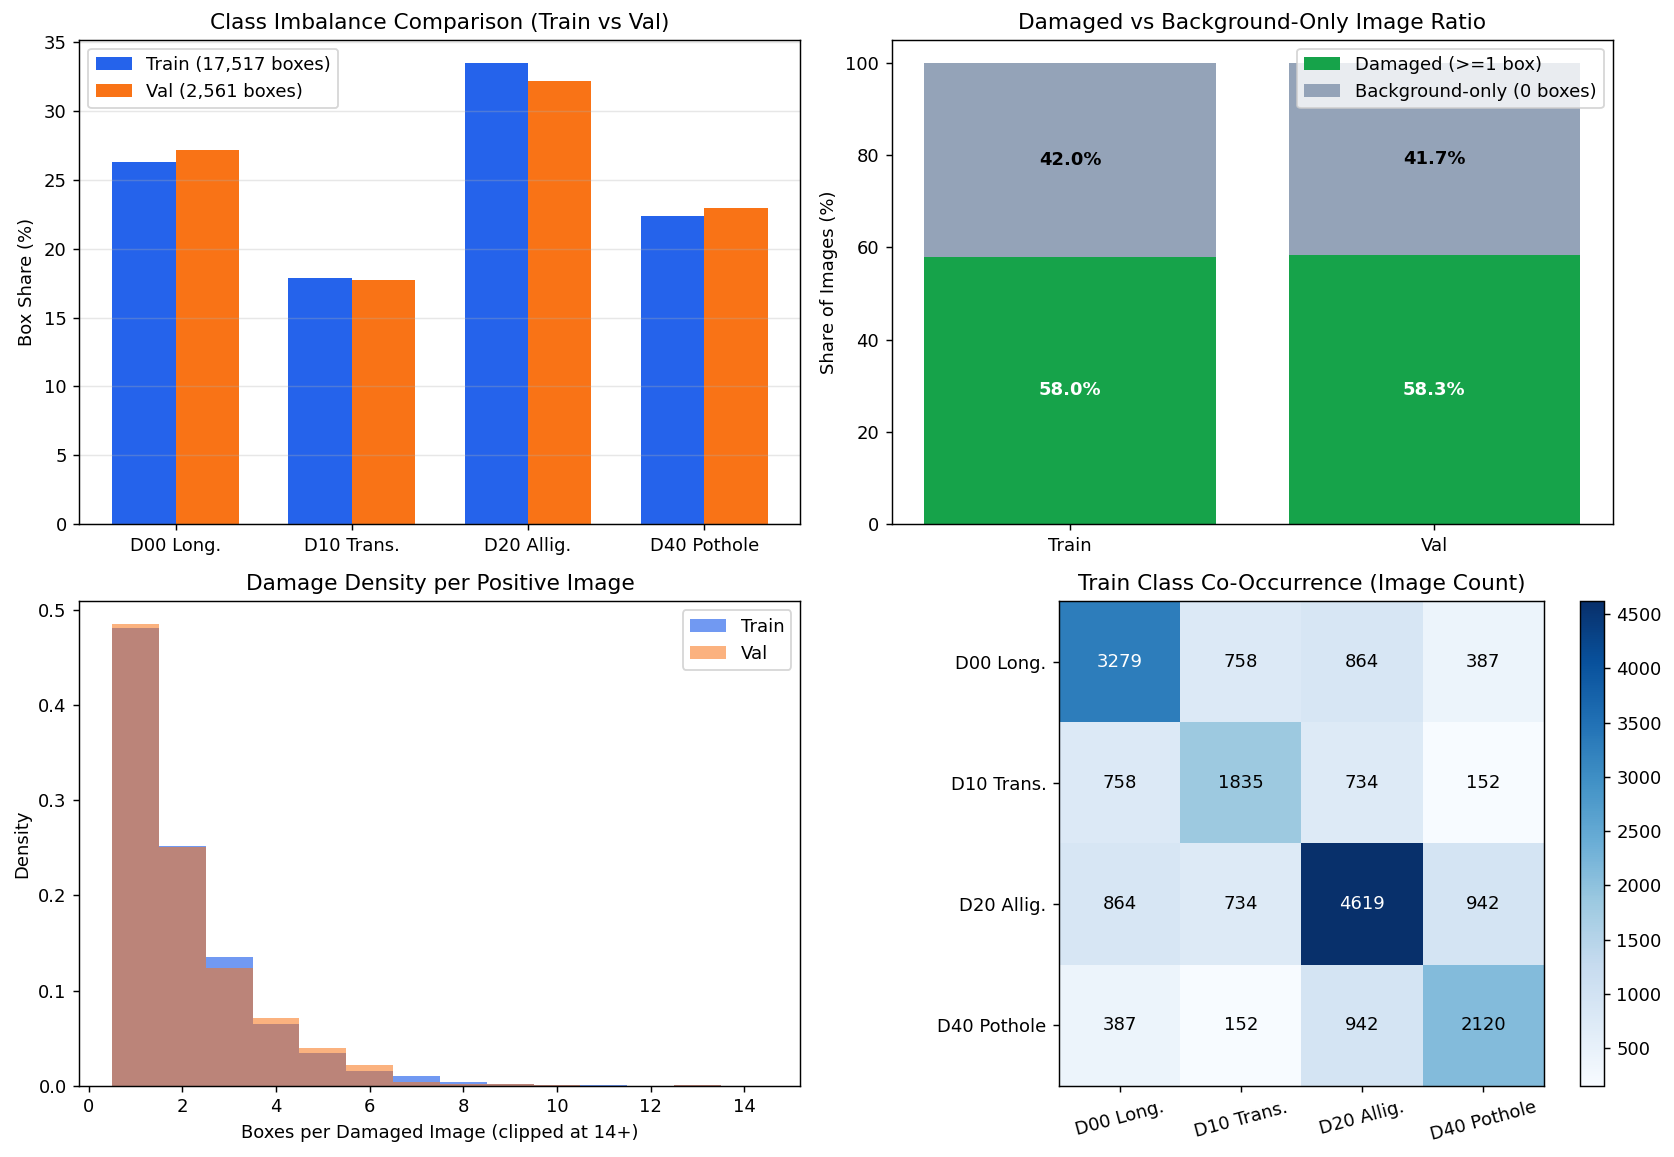

Train imbalance ratio: 1.872 | Val imbalance ratio: 1.815


In [6]:
_execute_stage(1, "def _label_overview(lbl_df: pd.DataFrame, meta_df: pd.DataFrame):\n    n_imgs = len(meta_df)\n    damaged_ids = set(lbl_df['image_id'].astype(str))\n    n_damaged = len(damaged_ids)\n    n_bg = max(0, n_imgs - n_damaged)\n    cls_counts = {c: int((lbl_df['class_id'] == c).sum()) for c in range(4)}\n    img_prev = {c: int(lbl_df.loc[lbl_df['class_id'] == c, 'image_id'].astype(str).nunique()) for c in range(4)}\n    bpi = lbl_df.groupby(lbl_df['image_id'].astype(str)).size().to_numpy()\n    coocc = np.zeros((4, 4), dtype=int)\n    for _, clist in lbl_df.groupby(lbl_df['image_id'].astype(str))['class_id'].apply(lambda s: sorted(set(int(x) for x in s))).items():\n        for i in clist:\n            for j in clist:\n                coocc[i, j] += 1\n    return {\n        'total_images': int(n_imgs),\n        'damaged_images': int(n_damaged),\n        'background_only_images': int(n_bg),\n        'background_only_pct': round(100.0 * n_bg / max(1, n_imgs), 2),\n        'total_boxes': int(len(lbl_df)),\n        'class_counts': {CLASS_NAMES[c]: cls_counts[c] for c in range(4)},\n        'class_pct': {CLASS_NAMES[c]: round(100.0 * cls_counts[c] / max(1, len(lbl_df)), 2) for c in range(4)},\n        'image_prevalence': {CLASS_NAMES[c]: img_prev[c] for c in range(4)},\n        'imbalance_ratio': round(max(cls_counts.values()) / max(1, min(cls_counts.values())), 3),\n        'boxes_per_damaged_image_mean': round(float(np.mean(bpi)), 3),\n        'boxes_per_damaged_image_max': int(np.max(bpi)),\n        'cooccurrence': coocc,\n        'bpi_array': bpi,\n    }\n\ntrain_lbl_ov = _label_overview(train_df, train_meta)\nval_lbl_ov = _label_overview(val_df, val_meta)\n\nfig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=130)\nx = np.arange(4)\nw = 0.36\ntrain_pcts = [train_lbl_ov['class_pct'][CLASS_NAMES[c]] for c in range(4)]\nval_pcts = [val_lbl_ov['class_pct'][CLASS_NAMES[c]] for c in range(4)]\naxes[0, 0].bar(x - w / 2, train_pcts, w, label='Train (17,517 boxes)', color='#2563eb')\naxes[0, 0].bar(x + w / 2, val_pcts, w, label='Val (2,561 boxes)', color='#f97316')\naxes[0, 0].set_xticks(x)\naxes[0, 0].set_xticklabels([CLASS_SHORT[c] for c in range(4)])\naxes[0, 0].set_ylabel('Box Share (%)')\naxes[0, 0].set_title('Class Imbalance Comparison (Train vs Val)')\naxes[0, 0].legend()\naxes[0, 0].grid(axis='y', alpha=0.3)\n\nsplit_names = ['Train', 'Val']\ndam_pcts = [100.0 - train_lbl_ov['background_only_pct'], 100.0 - val_lbl_ov['background_only_pct']]\nbg_pcts = [train_lbl_ov['background_only_pct'], val_lbl_ov['background_only_pct']]\naxes[0, 1].bar(split_names, dam_pcts, label='Damaged (>=1 box)', color='#16a34a')\naxes[0, 1].bar(split_names, bg_pcts, bottom=dam_pcts, label='Background-only (0 boxes)', color='#94a3b8')\nfor idx, (dp, bp) in enumerate(zip(dam_pcts, bg_pcts)):\n    axes[0, 1].text(idx, dp / 2, f'{dp:.1f}%', ha='center', va='center', color='white', fontweight='bold')\n    axes[0, 1].text(idx, dp + bp / 2, f'{bp:.1f}%', ha='center', va='center', color='black', fontweight='bold')\naxes[0, 1].set_ylabel('Share of Images (%)')\naxes[0, 1].set_title('Damaged vs Background-Only Image Ratio')\naxes[0, 1].legend()\n\nbins = np.arange(1, min(16, max(train_lbl_ov['bpi_array'].max(), val_lbl_ov['bpi_array'].max()) + 2)) - 0.5\naxes[1, 0].hist(np.clip(train_lbl_ov['bpi_array'], 1, 14), bins=bins, density=True, alpha=0.65, label='Train', color='#2563eb')\naxes[1, 0].hist(np.clip(val_lbl_ov['bpi_array'], 1, 14), bins=bins, density=True, alpha=0.55, label='Val', color='#f97316')\naxes[1, 0].set_xlabel('Boxes per Damaged Image (clipped at 14+)')\naxes[1, 0].set_ylabel('Density')\naxes[1, 0].set_title('Damage Density per Positive Image')\naxes[1, 0].legend()\n\nco = train_lbl_ov['cooccurrence']\nim = axes[1, 1].imshow(co, cmap='Blues')\naxes[1, 1].set_xticks(range(4))\naxes[1, 1].set_yticks(range(4))\naxes[1, 1].set_xticklabels([CLASS_SHORT[c] for c in range(4)], rotation=15)\naxes[1, 1].set_yticklabels([CLASS_SHORT[c] for c in range(4)])\nfor i in range(4):\n    for j in range(4):\n        axes[1, 1].text(j, i, str(co[i, j]), ha='center', va='center', color='white' if co[i, j] > co.max() * 0.5 else 'black')\naxes[1, 1].set_title('Train Class Co-Occurrence (Image Count)')\nfig.colorbar(im, ax=axes[1, 1], fraction=0.046)\n\nplt.tight_layout()\np1 = PLOTS_DIR / '01_class_imbalance_and_cooccurrence.png'\nplt.savefig(p1, dpi=150)\nplt.show()\nTASK_ARTIFACTS['plot_class_imbalance'] = f'03_results/runs/{RUN_ID}/eda_plots/{p1.name}'\nprint('Train imbalance ratio:', train_lbl_ov['imbalance_ratio'], '| Val imbalance ratio:', val_lbl_ov['imbalance_ratio'])")


## 3. Object Detection BBox Geometry, COCO Scales, Spatial Heatmaps & GT Overlap
Measure bounding-box dimensions, aspect ratios, COCO scale buckets (small/medium/large), road horizon y-bounds, spatial density heatmaps, and GT-box IoU overlaps.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
def _enrich_boxes(lbl_df: pd.DataFrame, meta_df: pd.DataFrame):
    m = lbl_df.merge(meta_df[['image_id', 'w', 'h']], on='image_id', how='left')
    m['bw'] = m['x_max'] - m['x_min']
    m['bh'] = m['y_max'] - m['y_min']
    m['area_px'] = m['bw'] * m['bh']
    m['nw'] = m['bw'] / m['w']
    m['nh'] = m['bh'] / m['h']
    m['xc'] = ((m['x_min'] + m['x_max']) / 2.0) / m['w']
    m['yc'] = ((m['y_min'] + m['y_max']) / 2.0) / m['h']
    m['y1_norm'] = m['y_min'] / m['h']
    m['ar'] = m['bw'] / np.maximum(1.0, m['bh'])
    m['coco_scale'] = np.where(m['area_px'] < 1024.0, 'Small (<32^2)',
                               np.where(m['area_px'] <= 9216.0, 'Medium (32^2-96^2)', 'Large (>96^2)'))
    return m

train_boxes = _enrich_boxes(train_df, train_meta)
val_boxes = _enrich_boxes(val_df, val_meta)

zero_neg = int(((train_boxes['bw'] <= 0) | (train_boxes['bh'] <= 0)).sum() + ((val_boxes['bw'] <= 0) | (val_boxes['bh'] <= 0)).sum())
oob = int(((train_boxes['x_min'] < 0) | (train_boxes['y_min'] < 0) | (train_boxes['x_max'] > train_boxes['w'] + 0.5) | (train_boxes['y_max'] > train_boxes['h'] + 0.5)).sum())

iou_05_same, iou_05_diff, iou_06_same, iou_06_diff = 0, 0, 0, 0
for _, grp in train_boxes.groupby('image_id'):
    if len(grp) < 2:
        continue
    b = grp[['x_min', 'y_min', 'x_max', 'y_max']].to_numpy(dtype=np.float64)
    cs = grp['class_id'].to_numpy(dtype=int)
    ar_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    for i in range(len(b)):
        for j in range(i + 1, len(b)):
            ix = max(0.0, min(b[i, 2], b[j, 2]) - max(b[i, 0], b[j, 0]))
            iy = max(0.0, min(b[i, 3], b[j, 3]) - max(b[i, 1], b[j, 1]))
            inter = ix * iy
            if inter <= 0:
                continue
            iou = inter / (ar_b[i] + ar_b[j] - inter)
            if iou >= 0.50:
                if cs[i] == cs[j]:
                    iou_05_same += 1
                else:
                    iou_05_diff += 1
            if iou >= 0.60:
                if cs[i] == cs[j]:
                    iou_06_same += 1
                else:
                    iou_06_diff += 1

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=130)
small_p, med_p, large_p = [], [], []
for c in range(4):
    sub = train_boxes[train_boxes['class_id'] == c]
    small_p.append(100.0 * float((sub['area_px'] < 1024.0).mean()))
    med_p.append(100.0 * float(((sub['area_px'] >= 1024.0) & (sub['area_px'] <= 9216.0)).mean()))
    large_p.append(100.0 * float((sub['area_px'] > 9216.0).mean()))
x = np.arange(4)
axes[0].bar(x, small_p, label='Small (<1024 px2)', color='#ef4444')
axes[0].bar(x, med_p, bottom=small_p, label='Medium (1024-9216)', color='#f59e0b')
axes[0].bar(x, large_p, bottom=np.array(small_p) + np.array(med_p), label='Large (>9216 px2)', color='#10b981')
axes[0].set_xticks(x)
axes[0].set_xticklabels([CLASS_SHORT[c] for c in range(4)])
axes[0].set_ylabel('Box Percentage (%)')
axes[0].set_title('COCO Pixel-Area Buckets (Train)')
axes[0].legend(fontsize=8)

ar_data = [np.clip(train_boxes.loc[train_boxes['class_id'] == c, 'ar'].to_numpy(), 0.05, 6.0) for c in range(4)]
axes[1].boxplot(ar_data, showfliers=False)
axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_xticklabels([CLASS_SHORT[c] for c in range(4)])
axes[1].axhline(1.0, color='gray', linestyle='--', linewidth=1)
axes[1].set_ylabel('Box Aspect Ratio (W / H)')
axes[1].set_title('BBox Aspect Ratio by Class (clipped 6x)')
axes[1].grid(axis='y', alpha=0.3)

for c in range(4):
    sub = train_boxes[train_boxes['class_id'] == c].sample(n=min(1000, int((train_boxes['class_id'] == c).sum())), random_state=SEED)
    axes[2].scatter(sub['nw'], sub['nh'], s=8, alpha=0.35, color=CLASS_COLORS[c], label=CLASS_SHORT[c])
axes[2].set_xlabel('Normalized Box Width (w / W)')
axes[2].set_ylabel('Normalized Box Height (h / H)')
axes[2].set_title('Normalized Box Width vs Height')
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)
plt.tight_layout()
p2 = PLOTS_DIR / '02_bbox_geometry_and_scales.png'
plt.savefig(p2, dpi=150)
plt.show()
TASK_ARTIFACTS['plot_bbox_geometry'] = f'03_results/runs/{RUN_ID}/eda_plots/{p2.name}'

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), dpi=130)
for c in range(4):
    sub = train_boxes[train_boxes['class_id'] == c]
    h2d, _, _ = np.histogram2d(sub['xc'], sub['yc'], bins=24, range=[[0.0, 1.0], [0.0, 1.0]])
    axes[c].imshow(h2d.T, origin='upper', extent=[0, 1, 1, 0], cmap='inferno')
    axes[c].set_title(f'{CLASS_SHORT[c]} Centers')
    axes[c].set_xlabel('x / W')
    if c == 0:
        axes[c].set_ylabel('y / H')
plt.tight_layout()
p3 = PLOTS_DIR / '03_spatial_center_heatmaps.png'
plt.savefig(p3, dpi=150)
plt.show()
TASK_ARTIFACTS['plot_spatial_heatmaps'] = f'03_results/runs/{RUN_ID}/eda_plots/{p3.name}'

print('Zero/Neg boxes:', zero_neg, '| Out-of-bounds:', oob)
print('Train y_min/H p01/p05/p10:', np.round(np.percentile(train_boxes['y1_norm'], [1, 5, 10]), 3).tolist())
print(f'GT IoU >= 0.50 pairs: same_class={iou_05_same}, cross_class={iou_05_diff} | IoU >= 0.60: same={iou_06_same}, cross={iou_06_diff}')
```


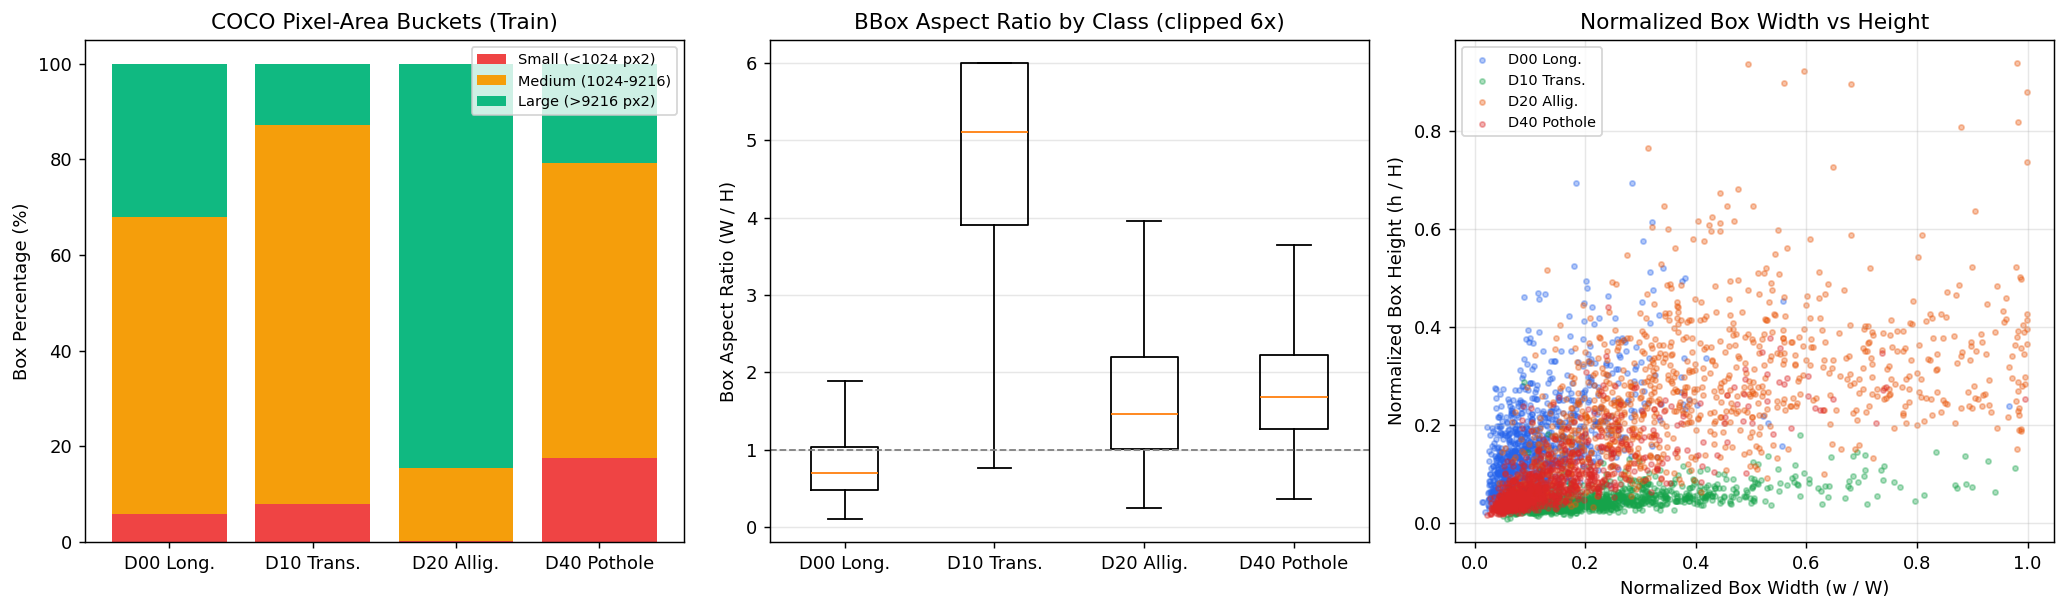

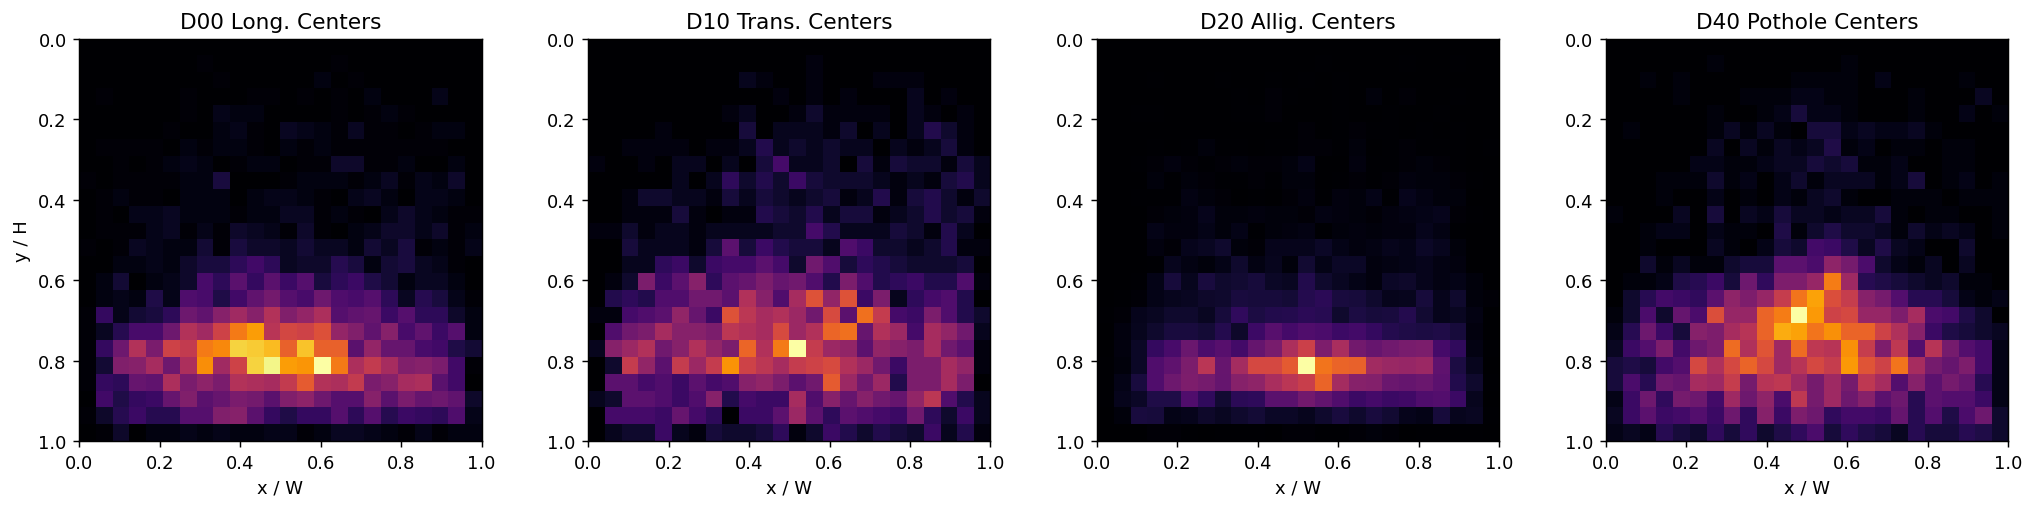

Zero/Neg boxes: 0 | Out-of-bounds: 0
Train y_min/H p01/p05/p10: [0.122, 0.3, 0.468]
GT IoU >= 0.50 pairs: same_class=13, cross_class=43 | IoU >= 0.60: same=3, cross=35


In [7]:
_execute_stage(2, "def _enrich_boxes(lbl_df: pd.DataFrame, meta_df: pd.DataFrame):\n    m = lbl_df.merge(meta_df[['image_id', 'w', 'h']], on='image_id', how='left')\n    m['bw'] = m['x_max'] - m['x_min']\n    m['bh'] = m['y_max'] - m['y_min']\n    m['area_px'] = m['bw'] * m['bh']\n    m['nw'] = m['bw'] / m['w']\n    m['nh'] = m['bh'] / m['h']\n    m['xc'] = ((m['x_min'] + m['x_max']) / 2.0) / m['w']\n    m['yc'] = ((m['y_min'] + m['y_max']) / 2.0) / m['h']\n    m['y1_norm'] = m['y_min'] / m['h']\n    m['ar'] = m['bw'] / np.maximum(1.0, m['bh'])\n    m['coco_scale'] = np.where(m['area_px'] < 1024.0, 'Small (<32^2)',\n                               np.where(m['area_px'] <= 9216.0, 'Medium (32^2-96^2)', 'Large (>96^2)'))\n    return m\n\ntrain_boxes = _enrich_boxes(train_df, train_meta)\nval_boxes = _enrich_boxes(val_df, val_meta)\n\nzero_neg = int(((train_boxes['bw'] <= 0) | (train_boxes['bh'] <= 0)).sum() + ((val_boxes['bw'] <= 0) | (val_boxes['bh'] <= 0)).sum())\noob = int(((train_boxes['x_min'] < 0) | (train_boxes['y_min'] < 0) | (train_boxes['x_max'] > train_boxes['w'] + 0.5) | (train_boxes['y_max'] > train_boxes['h'] + 0.5)).sum())\n\niou_05_same, iou_05_diff, iou_06_same, iou_06_diff = 0, 0, 0, 0\nfor _, grp in train_boxes.groupby('image_id'):\n    if len(grp) < 2:\n        continue\n    b = grp[['x_min', 'y_min', 'x_max', 'y_max']].to_numpy(dtype=np.float64)\n    cs = grp['class_id'].to_numpy(dtype=int)\n    ar_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])\n    for i in range(len(b)):\n        for j in range(i + 1, len(b)):\n            ix = max(0.0, min(b[i, 2], b[j, 2]) - max(b[i, 0], b[j, 0]))\n            iy = max(0.0, min(b[i, 3], b[j, 3]) - max(b[i, 1], b[j, 1]))\n            inter = ix * iy\n            if inter <= 0:\n                continue\n            iou = inter / (ar_b[i] + ar_b[j] - inter)\n            if iou >= 0.50:\n                if cs[i] == cs[j]:\n                    iou_05_same += 1\n                else:\n                    iou_05_diff += 1\n            if iou >= 0.60:\n                if cs[i] == cs[j]:\n                    iou_06_same += 1\n                else:\n                    iou_06_diff += 1\n\nfig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=130)\nsmall_p, med_p, large_p = [], [], []\nfor c in range(4):\n    sub = train_boxes[train_boxes['class_id'] == c]\n    small_p.append(100.0 * float((sub['area_px'] < 1024.0).mean()))\n    med_p.append(100.0 * float(((sub['area_px'] >= 1024.0) & (sub['area_px'] <= 9216.0)).mean()))\n    large_p.append(100.0 * float((sub['area_px'] > 9216.0).mean()))\nx = np.arange(4)\naxes[0].bar(x, small_p, label='Small (<1024 px2)', color='#ef4444')\naxes[0].bar(x, med_p, bottom=small_p, label='Medium (1024-9216)', color='#f59e0b')\naxes[0].bar(x, large_p, bottom=np.array(small_p) + np.array(med_p), label='Large (>9216 px2)', color='#10b981')\naxes[0].set_xticks(x)\naxes[0].set_xticklabels([CLASS_SHORT[c] for c in range(4)])\naxes[0].set_ylabel('Box Percentage (%)')\naxes[0].set_title('COCO Pixel-Area Buckets (Train)')\naxes[0].legend(fontsize=8)\n\nar_data = [np.clip(train_boxes.loc[train_boxes['class_id'] == c, 'ar'].to_numpy(), 0.05, 6.0) for c in range(4)]\naxes[1].boxplot(ar_data, showfliers=False)\naxes[1].set_xticks([1, 2, 3, 4])\naxes[1].set_xticklabels([CLASS_SHORT[c] for c in range(4)])\naxes[1].axhline(1.0, color='gray', linestyle='--', linewidth=1)\naxes[1].set_ylabel('Box Aspect Ratio (W / H)')\naxes[1].set_title('BBox Aspect Ratio by Class (clipped 6x)')\naxes[1].grid(axis='y', alpha=0.3)\n\nfor c in range(4):\n    sub = train_boxes[train_boxes['class_id'] == c].sample(n=min(1000, int((train_boxes['class_id'] == c).sum())), random_state=SEED)\n    axes[2].scatter(sub['nw'], sub['nh'], s=8, alpha=0.35, color=CLASS_COLORS[c], label=CLASS_SHORT[c])\naxes[2].set_xlabel('Normalized Box Width (w / W)')\naxes[2].set_ylabel('Normalized Box Height (h / H)')\naxes[2].set_title('Normalized Box Width vs Height')\naxes[2].legend(fontsize=8)\naxes[2].grid(alpha=0.3)\nplt.tight_layout()\np2 = PLOTS_DIR / '02_bbox_geometry_and_scales.png'\nplt.savefig(p2, dpi=150)\nplt.show()\nTASK_ARTIFACTS['plot_bbox_geometry'] = f'03_results/runs/{RUN_ID}/eda_plots/{p2.name}'\n\nfig, axes = plt.subplots(1, 4, figsize=(16, 3.8), dpi=130)\nfor c in range(4):\n    sub = train_boxes[train_boxes['class_id'] == c]\n    h2d, _, _ = np.histogram2d(sub['xc'], sub['yc'], bins=24, range=[[0.0, 1.0], [0.0, 1.0]])\n    axes[c].imshow(h2d.T, origin='upper', extent=[0, 1, 1, 0], cmap='inferno')\n    axes[c].set_title(f'{CLASS_SHORT[c]} Centers')\n    axes[c].set_xlabel('x / W')\n    if c == 0:\n        axes[c].set_ylabel('y / H')\nplt.tight_layout()\np3 = PLOTS_DIR / '03_spatial_center_heatmaps.png'\nplt.savefig(p3, dpi=150)\nplt.show()\nTASK_ARTIFACTS['plot_spatial_heatmaps'] = f'03_results/runs/{RUN_ID}/eda_plots/{p3.name}'\n\nprint('Zero/Neg boxes:', zero_neg, '| Out-of-bounds:', oob)\nprint('Train y_min/H p01/p05/p10:', np.round(np.percentile(train_boxes['y1_norm'], [1, 5, 10]), 3).tolist())\nprint(f'GT IoU >= 0.50 pairs: same_class={iou_05_same}, cross_class={iou_05_diff} | IoU >= 0.60: same={iou_06_same}, cross={iou_06_diff}')")


## 4. Image Dimensions, Aspect Ratios & Domain Parity (Train vs Val vs Test)
Compare image widths, heights, resolution distribution, and aspect ratios across Train, Val, and Test to detect resolution shifts or regional splits.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
def _res_table(meta_df: pd.DataFrame):
    s = meta_df.apply(lambda r: f"{int(r['w'])}x{int(r['h'])}", axis=1)
    vc = s.value_counts()
    return (100.0 * vc / len(meta_df)).round(2), vc

tr_pct, tr_cnt = _res_table(train_meta)
va_pct, va_cnt = _res_table(val_meta)
te_pct, te_cnt = _res_table(test_meta)

all_res = sorted(set(tr_pct.head(6).index) | set(va_pct.head(6).index) | set(te_pct.head(6).index),
                 key=lambda k: -(tr_pct.get(k, 0) + va_pct.get(k, 0) + te_pct.get(k, 0)))
res_df = pd.DataFrame({
    'Train %': [float(tr_pct.get(k, 0.0)) for k in all_res],
    'Val %': [float(va_pct.get(k, 0.0)) for k in all_res],
    'Test %': [float(te_pct.get(k, 0.0)) for k in all_res],
}, index=all_res)
print('Top Resolution Share (%) Across Splits:')
print(res_df.to_string())

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=130)
x = np.arange(len(all_res))
w = 0.26
ax.bar(x - w, res_df['Train %'], w, label='Train (14,691)', color='#2563eb')
ax.bar(x, res_df['Val %'], w, label='Val (2,150)', color='#f97316')
ax.bar(x + w, res_df['Test %'], w, label='Test (4,200)', color='#10b981')
ax.set_xticks(x)
ax.set_xticklabels(all_res, rotation=20)
ax.set_ylabel('Image Share (%)')
ax.set_title('Image Resolution Distribution Parity (Train vs Val vs Test)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
p4 = PLOTS_DIR / '04_resolution_parity_train_val_test.png'
plt.savefig(p4, dpi=150)
plt.show()
TASK_ARTIFACTS['plot_resolution_parity'] = f'03_results/runs/{RUN_ID}/eda_plots/{p4.name}'
```


Top Resolution Share (%) Across Splits:
           Train %  Val %  Test %
600x600      62.10  60.65   61.64
720x720      36.46  37.21   36.90
1024x1024     0.67   1.02    0.64
540x540       0.57   0.88    0.50
1080x1080     0.20   0.23    0.31


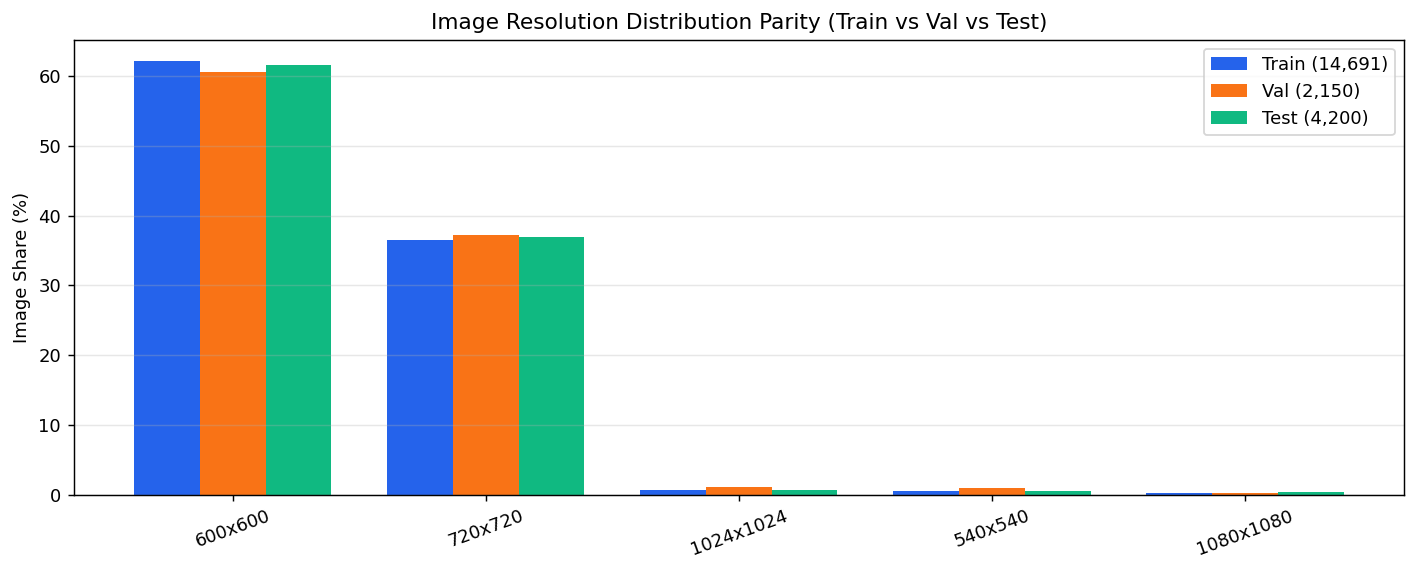

In [8]:
_execute_stage(3, 'def _res_table(meta_df: pd.DataFrame):\n    s = meta_df.apply(lambda r: f"{int(r[\'w\'])}x{int(r[\'h\'])}", axis=1)\n    vc = s.value_counts()\n    return (100.0 * vc / len(meta_df)).round(2), vc\n\ntr_pct, tr_cnt = _res_table(train_meta)\nva_pct, va_cnt = _res_table(val_meta)\nte_pct, te_cnt = _res_table(test_meta)\n\nall_res = sorted(set(tr_pct.head(6).index) | set(va_pct.head(6).index) | set(te_pct.head(6).index),\n                 key=lambda k: -(tr_pct.get(k, 0) + va_pct.get(k, 0) + te_pct.get(k, 0)))\nres_df = pd.DataFrame({\n    \'Train %\': [float(tr_pct.get(k, 0.0)) for k in all_res],\n    \'Val %\': [float(va_pct.get(k, 0.0)) for k in all_res],\n    \'Test %\': [float(te_pct.get(k, 0.0)) for k in all_res],\n}, index=all_res)\nprint(\'Top Resolution Share (%) Across Splits:\')\nprint(res_df.to_string())\n\nfig, ax = plt.subplots(figsize=(11, 4.5), dpi=130)\nx = np.arange(len(all_res))\nw = 0.26\nax.bar(x - w, res_df[\'Train %\'], w, label=\'Train (14,691)\', color=\'#2563eb\')\nax.bar(x, res_df[\'Val %\'], w, label=\'Val (2,150)\', color=\'#f97316\')\nax.bar(x + w, res_df[\'Test %\'], w, label=\'Test (4,200)\', color=\'#10b981\')\nax.set_xticks(x)\nax.set_xticklabels(all_res, rotation=20)\nax.set_ylabel(\'Image Share (%)\')\nax.set_title(\'Image Resolution Distribution Parity (Train vs Val vs Test)\')\nax.legend()\nax.grid(axis=\'y\', alpha=0.3)\nplt.tight_layout()\np4 = PLOTS_DIR / \'04_resolution_parity_train_val_test.png\'\nplt.savefig(p4, dpi=150)\nplt.show()\nTASK_ARTIFACTS[\'plot_resolution_parity\'] = f\'03_results/runs/{RUN_ID}/eda_plots/{p4.name}\'')


## 5. Image Quality & Hidden Degradation Shift (BPP, Brightness, Sharpness, Noise)
Measure full-split JPEG bytes-per-pixel and stratified 1,000-image pixel quality statistics (brightness, contrast, Laplacian sharpness, noise MAD) across Train, Val, and Test.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
def _sample_quality(meta_df: pd.DataFrame, sample_n: int):
    sub = meta_df.sample(n=min(sample_n, len(meta_df)), random_state=SEED)
    def _eval_one(path_str: str):
        with Image.open(path_str) as im:
            arr = np.asarray(im.convert('RGB'), dtype=np.float32)
        luma = 0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2]
        lap = luma[:-2, 1:-1] + luma[2:, 1:-1] + luma[1:-1, :-2] + luma[1:-1, 2:] - 4.0 * luma[1:-1, 1:-1]
        blur3 = (
            luma[:-2, :-2] + luma[:-2, 1:-1] + luma[:-2, 2:]
            + luma[1:-1, :-2] + luma[1:-1, 1:-1] + luma[1:-1, 2:]
            + luma[2:, :-2] + luma[2:, 1:-1] + luma[2:, 2:]
        ) / 9.0
        noise_mad = float(np.mean(np.abs(luma[1:-1, 1:-1] - blur3)))
        return {
            'path': path_str,
            'mean_luma': float(luma.mean()),
            'std_luma': float(luma.std()),
            'lap_var': float(np.var(lap)),
            'noise_mad': noise_mad,
        }
    with ThreadPoolExecutor(max_workers=8) as pool:
        q = list(pool.map(_eval_one, sub['path'].tolist()))
    return pd.DataFrame(q).merge(sub[['path', 'bpp', 'size_kb']], on='path')

train_q = _sample_quality(train_meta, QUALITY_SAMPLE_N)
val_q = _sample_quality(val_meta, QUALITY_SAMPLE_N)
test_q = _sample_quality(test_meta, QUALITY_SAMPLE_N)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), dpi=130)
for ax, col, title, rng in [
    (axes[0, 0], 'bpp', 'JPEG Bytes-per-Pixel (All Images: Compression Tail)', (0.0, 0.9)),
    (axes[0, 1], 'mean_luma', 'Mean Brightness Luma (0-255: Low-Light Tail)', (0.0, 255.0)),
    (axes[1, 0], 'lap_var', 'Sharpness (Laplacian Variance, clipped 0-2500)', (0.0, 2500.0)),
    (axes[1, 1], 'noise_mad', 'High-Frequency Noise Residual MAD (clipped 0-16)', (0.0, 16.0)),
]:
    if col == 'bpp':
        s_tr, s_va, s_te = train_meta[col], val_meta[col], test_meta[col]
    else:
        s_tr, s_va, s_te = train_q[col], val_q[col], test_q[col]
    ax.hist(np.clip(s_tr, rng[0], rng[1]), bins=40, density=True, histtype='step', linewidth=1.8, label='Train', color='#2563eb')
    ax.hist(np.clip(s_va, rng[0], rng[1]), bins=40, density=True, histtype='step', linewidth=1.8, label='Val', color='#f97316')
    ax.hist(np.clip(s_te, rng[0], rng[1]), bins=40, density=True, histtype='step', linewidth=2.0, label='Test', color='#dc2626')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
p5 = PLOTS_DIR / '05_quality_and_degradation_shift.png'
plt.savefig(p5, dpi=150)
plt.show()
TASK_ARTIFACTS['plot_quality_shift'] = f'03_results/runs/{RUN_ID}/eda_plots/{p5.name}'

val_bpp_p05 = float(np.percentile(val_meta['bpp'], 5))
test_bpp_p05 = float(np.percentile(test_meta['bpp'], 5))
print(f'BPP p05 -> Train: {np.percentile(train_meta["bpp"], 5):.4f} | Val: {val_bpp_p05:.4f} | Test: {test_bpp_p05:.4f}')
print(f'Low BPP (<0.12) % -> Train: {(train_meta["bpp"]<0.12).mean()*100:.2f}% | Val: {(val_meta["bpp"]<0.12).mean()*100:.2f}% | Test: {(test_meta["bpp"]<0.12).mean()*100:.2f}%')
print(f'Dark Luma (<65) % -> Train: {(train_q["mean_luma"]<65).mean()*100:.2f}% | Val: {(val_q["mean_luma"]<65).mean()*100:.2f}% | Test: {(test_q["mean_luma"]<65).mean()*100:.2f}%')
check_budget()
```


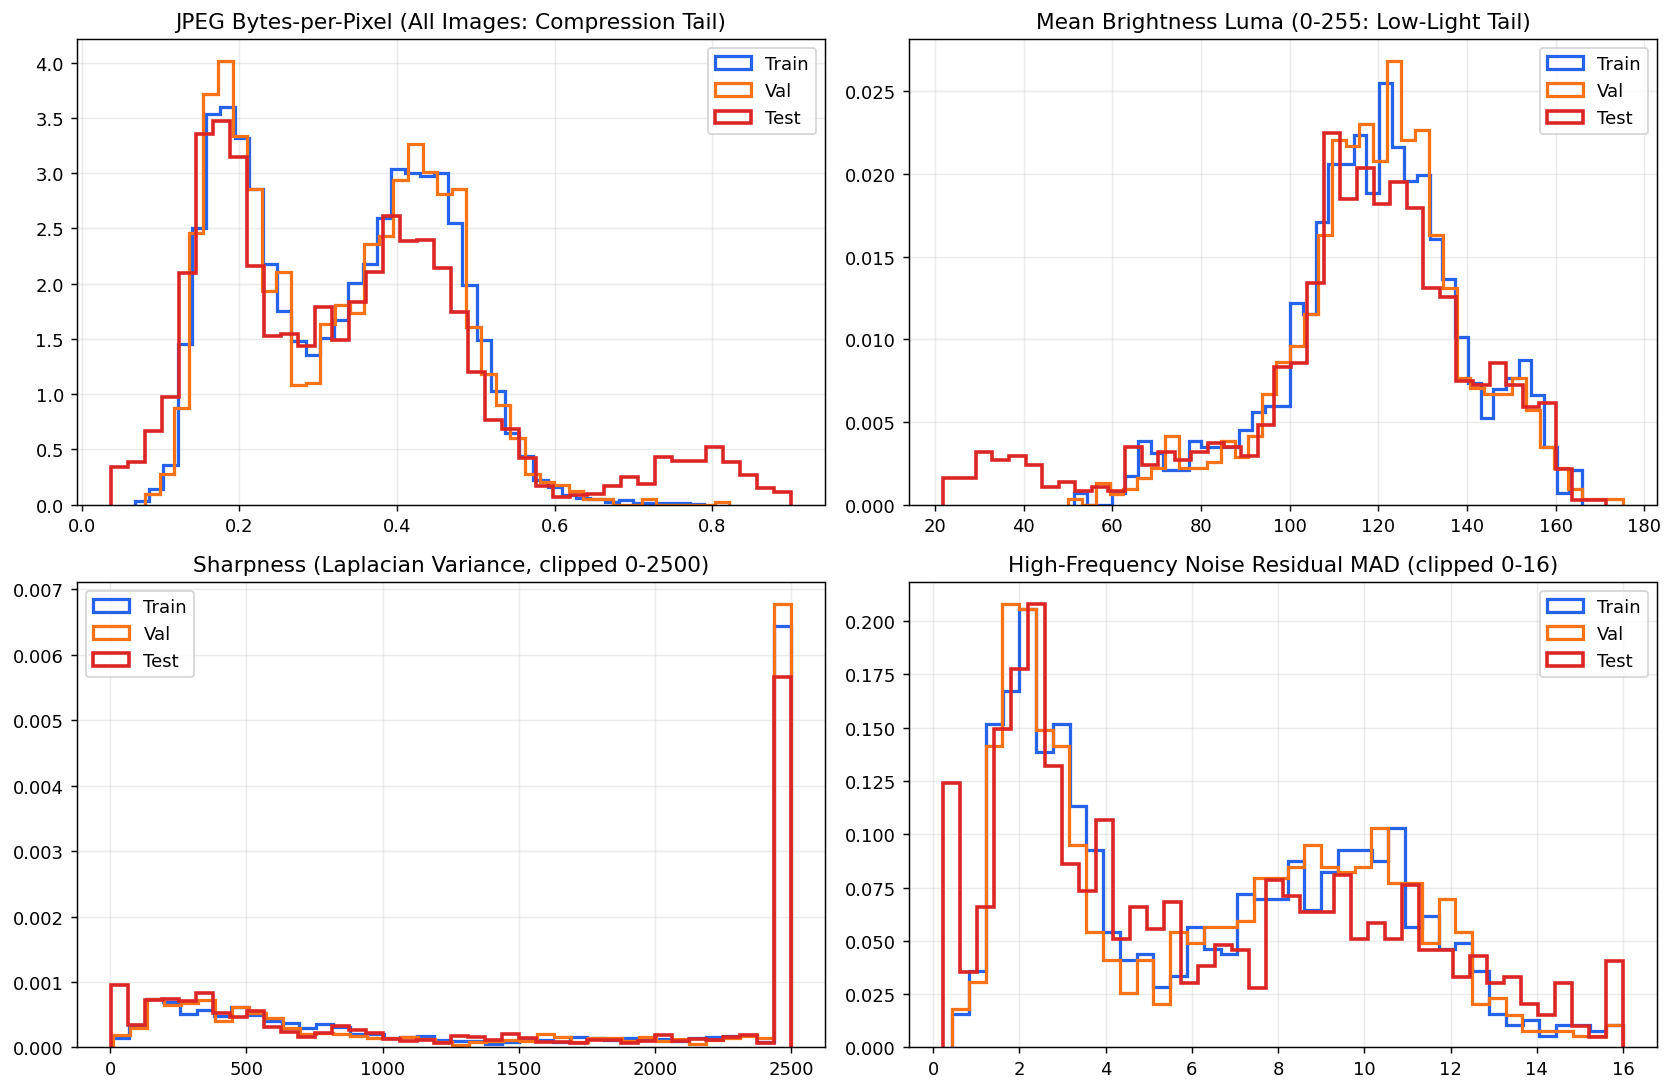

BPP p05 -> Train: 0.1460 | Val: 0.1486 | Test: 0.1227
Low BPP (<0.12) % -> Train: 0.87% | Val: 0.84% | Test: 4.69%
Dark Luma (<65) % -> Train: 0.60% | Val: 0.90% | Test: 7.80%


In [9]:
_execute_stage(4, 'def _sample_quality(meta_df: pd.DataFrame, sample_n: int):\n    sub = meta_df.sample(n=min(sample_n, len(meta_df)), random_state=SEED)\n    def _eval_one(path_str: str):\n        with Image.open(path_str) as im:\n            arr = np.asarray(im.convert(\'RGB\'), dtype=np.float32)\n        luma = 0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2]\n        lap = luma[:-2, 1:-1] + luma[2:, 1:-1] + luma[1:-1, :-2] + luma[1:-1, 2:] - 4.0 * luma[1:-1, 1:-1]\n        blur3 = (\n            luma[:-2, :-2] + luma[:-2, 1:-1] + luma[:-2, 2:]\n            + luma[1:-1, :-2] + luma[1:-1, 1:-1] + luma[1:-1, 2:]\n            + luma[2:, :-2] + luma[2:, 1:-1] + luma[2:, 2:]\n        ) / 9.0\n        noise_mad = float(np.mean(np.abs(luma[1:-1, 1:-1] - blur3)))\n        return {\n            \'path\': path_str,\n            \'mean_luma\': float(luma.mean()),\n            \'std_luma\': float(luma.std()),\n            \'lap_var\': float(np.var(lap)),\n            \'noise_mad\': noise_mad,\n        }\n    with ThreadPoolExecutor(max_workers=8) as pool:\n        q = list(pool.map(_eval_one, sub[\'path\'].tolist()))\n    return pd.DataFrame(q).merge(sub[[\'path\', \'bpp\', \'size_kb\']], on=\'path\')\n\ntrain_q = _sample_quality(train_meta, QUALITY_SAMPLE_N)\nval_q = _sample_quality(val_meta, QUALITY_SAMPLE_N)\ntest_q = _sample_quality(test_meta, QUALITY_SAMPLE_N)\n\nfig, axes = plt.subplots(2, 2, figsize=(13, 8.5), dpi=130)\nfor ax, col, title, rng in [\n    (axes[0, 0], \'bpp\', \'JPEG Bytes-per-Pixel (All Images: Compression Tail)\', (0.0, 0.9)),\n    (axes[0, 1], \'mean_luma\', \'Mean Brightness Luma (0-255: Low-Light Tail)\', (0.0, 255.0)),\n    (axes[1, 0], \'lap_var\', \'Sharpness (Laplacian Variance, clipped 0-2500)\', (0.0, 2500.0)),\n    (axes[1, 1], \'noise_mad\', \'High-Frequency Noise Residual MAD (clipped 0-16)\', (0.0, 16.0)),\n]:\n    if col == \'bpp\':\n        s_tr, s_va, s_te = train_meta[col], val_meta[col], test_meta[col]\n    else:\n        s_tr, s_va, s_te = train_q[col], val_q[col], test_q[col]\n    ax.hist(np.clip(s_tr, rng[0], rng[1]), bins=40, density=True, histtype=\'step\', linewidth=1.8, label=\'Train\', color=\'#2563eb\')\n    ax.hist(np.clip(s_va, rng[0], rng[1]), bins=40, density=True, histtype=\'step\', linewidth=1.8, label=\'Val\', color=\'#f97316\')\n    ax.hist(np.clip(s_te, rng[0], rng[1]), bins=40, density=True, histtype=\'step\', linewidth=2.0, label=\'Test\', color=\'#dc2626\')\n    ax.set_title(title)\n    ax.legend()\n    ax.grid(alpha=0.25)\nplt.tight_layout()\np5 = PLOTS_DIR / \'05_quality_and_degradation_shift.png\'\nplt.savefig(p5, dpi=150)\nplt.show()\nTASK_ARTIFACTS[\'plot_quality_shift\'] = f\'03_results/runs/{RUN_ID}/eda_plots/{p5.name}\'\n\nval_bpp_p05 = float(np.percentile(val_meta[\'bpp\'], 5))\ntest_bpp_p05 = float(np.percentile(test_meta[\'bpp\'], 5))\nprint(f\'BPP p05 -> Train: {np.percentile(train_meta["bpp"], 5):.4f} | Val: {val_bpp_p05:.4f} | Test: {test_bpp_p05:.4f}\')\nprint(f\'Low BPP (<0.12) % -> Train: {(train_meta["bpp"]<0.12).mean()*100:.2f}% | Val: {(val_meta["bpp"]<0.12).mean()*100:.2f}% | Test: {(test_meta["bpp"]<0.12).mean()*100:.2f}%\')\nprint(f\'Dark Luma (<65) % -> Train: {(train_q["mean_luma"]<65).mean()*100:.2f}% | Val: {(val_q["mean_luma"]<65).mean()*100:.2f}% | Test: {(test_q["mean_luma"]<65).mean()*100:.2f}%\')\ncheck_budget()')


## 6. Visual Sample Grids (Per-Class GT Overlays & Degraded Test Tail) & Export
Render visual inspection grids of ground-truth boxes per class and extreme degraded test samples, export full EDA JSON, and assign finite metrics.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
n_cols = int(CONFIG.get('experiment', {}).get('max_grid_images_per_class', 6))
fig, axes = plt.subplots(4, n_cols, figsize=(3.0 * n_cols, 11.5), dpi=120)
for c in range(4):
    cand_ids = train_boxes.loc[train_boxes['class_id'] == c, 'image_id'].drop_duplicates().sample(
        n=min(n_cols, int(train_boxes.loc[train_boxes['class_id'] == c, 'image_id'].nunique())), random_state=SEED + c
    ).tolist()
    for j in range(n_cols):
        ax = axes[c, j]
        ax.axis('off')
        if j >= len(cand_ids):
            continue
        iid = cand_ids[j]
        img_path = train_meta.loc[train_meta['image_id'] == iid, 'path'].iloc[0]
        with Image.open(img_path) as im:
            ax.imshow(im.convert('RGB'))
        sub_b = train_boxes[train_boxes['image_id'] == iid]
        for _, row in sub_b.iterrows():
            bc = CLASS_COLORS[int(row['class_id'])]
            rect = patches.Rectangle((row['x_min'], row['y_min']), row['bw'], row['bh'], linewidth=2, edgecolor=bc, facecolor='none')
            ax.add_patch(rect)
            ax.text(row['x_min'], max(12, row['y_min'] - 3), CLASS_SHORT[int(row['class_id'])],
                    color='white', fontsize=7, bbox=dict(facecolor=bc, alpha=0.8, pad=1, edgecolor='none'))
        if j == 0:
            ax.set_title(f'{CLASS_SHORT[c]} ({iid})', fontsize=9)
        else:
            ax.set_title(iid, fontsize=8)
plt.tight_layout()
p6 = PLOTS_DIR / '06_sample_gt_boxes_by_class.png'
plt.savefig(p6, dpi=140)
plt.show()
TASK_ARTIFACTS['plot_sample_gt_grid'] = f'03_results/runs/{RUN_ID}/eda_plots/{p6.name}'

extreme_specs = [
    ('Lowest BPP (Compression)', test_q.nsmallest(4, 'bpp')),
    ('Lowest Luma (Dark/Low-Light)', test_q.nsmallest(4, 'mean_luma')),
    ('Lowest LapVar (Blurry)', test_q.nsmallest(4, 'lap_var')),
    ('Highest Noise MAD (Noisy)', test_q.nlargest(4, 'noise_mad')),
]
fig, axes = plt.subplots(4, 4, figsize=(13, 12), dpi=120)
for r_idx, (label, df_sub) in enumerate(extreme_specs):
    for c_idx in range(4):
        ax = axes[r_idx, c_idx]
        ax.axis('off')
        if c_idx >= len(df_sub):
            continue
        row = df_sub.iloc[c_idx]
        with Image.open(row['path']) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f"{Path(row['path']).stem}\nbpp={row['bpp']:.2f} lum={row['mean_luma']:.0f} lap={row['lap_var']:.0f} n={row['noise_mad']:.1f}", fontsize=7.5)
        if c_idx == 0:
            ax.text(5, 22, label, color='yellow', fontsize=8.5, fontweight='bold', bbox=dict(facecolor='black', alpha=0.7, pad=2))
plt.tight_layout()
p7 = PLOTS_DIR / '07_test_degraded_tail_samples.png'
plt.savefig(p7, dpi=140)
plt.show()
TASK_ARTIFACTS['plot_test_degraded_samples'] = f'03_results/runs/{RUN_ID}/eda_plots/{p7.name}'

full_report = {
    'integrity': integrity_report,
    'train_labels': {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in train_lbl_ov.items() if k != 'bpi_array'},
    'val_labels': {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in val_lbl_ov.items() if k != 'bpi_array'},
    'zero_or_neg_boxes': zero_neg,
    'out_of_bounds_boxes': oob,
    'gt_iou_overlaps': {'iou_05_same': iou_05_same, 'iou_05_diff': iou_05_diff, 'iou_06_same': iou_06_same, 'iou_06_diff': iou_06_diff},
    'test_bpp_p05': test_bpp_p05,
    'val_bpp_p05': val_bpp_p05,
}
eda_json_path = RUN_DRIVE_DIR / 'full_eda_report.json'
eda_json_path.write_text(json.dumps(full_report, indent=2), encoding='utf-8')
TASK_ARTIFACTS['full_eda_report'] = f'03_results/runs/{RUN_ID}/full_eda_report.json'

metrics.update({
    'train_images': int(len(train_meta)),
    'val_images': int(len(val_meta)),
    'test_images': int(len(test_meta)),
    'train_boxes': int(len(train_df)),
    'val_boxes': int(len(val_df)),
    'class_imbalance_ratio_train': float(train_lbl_ov['imbalance_ratio']),
    'background_only_pct_val': float(val_lbl_ov['background_only_pct']),
    'cross_split_exact_dupes': int(integrity_report['cross_dups_train_val'] + integrity_report['cross_dups_train_test'] + integrity_report['cross_dups_val_test']),
    'test_low_bpp_p05': float(round(test_bpp_p05, 5)),
    'val_low_bpp_p05': float(round(val_bpp_p05, 5)),
})
print('EDA Complete. Metrics:', json.dumps(metrics, indent=2))
```


In [10]:
_execute_stage(5, 'n_cols = int(CONFIG.get(\'experiment\', {}).get(\'max_grid_images_per_class\', 6))\nfig, axes = plt.subplots(4, n_cols, figsize=(3.0 * n_cols, 11.5), dpi=120)\nfor c in range(4):\n    cand_ids = train_boxes.loc[train_boxes[\'class_id\'] == c, \'image_id\'].drop_duplicates().sample(\n        n=min(n_cols, int(train_boxes.loc[train_boxes[\'class_id\'] == c, \'image_id\'].nunique())), random_state=SEED + c\n    ).tolist()\n    for j in range(n_cols):\n        ax = axes[c, j]\n        ax.axis(\'off\')\n        if j >= len(cand_ids):\n            continue\n        iid = cand_ids[j]\n        img_path = train_meta.loc[train_meta[\'image_id\'] == iid, \'path\'].iloc[0]\n        with Image.open(img_path) as im:\n            ax.imshow(im.convert(\'RGB\'))\n        sub_b = train_boxes[train_boxes[\'image_id\'] == iid]\n        for _, row in sub_b.iterrows():\n            bc = CLASS_COLORS[int(row[\'class_id\'])]\n            rect = patches.Rectangle((row[\'x_min\'], row[\'y_min\']), row[\'bw\'], row[\'bh\'], linewidth=2, edgecolor=bc, facecolor=\'none\')\n            ax.add_patch(rect)\n            ax.text(row[\'x_min\'], max(12, row[\'y_min\'] - 3), CLASS_SHORT[int(row[\'class_id\'])],\n                    color=\'white\', fontsize=7, bbox=dict(facecolor=bc, alpha=0.8, pad=1, edgecolor=\'none\'))\n        if j == 0:\n            ax.set_title(f\'{CLASS_SHORT[c]} ({iid})\', fontsize=9)\n        else:\n            ax.set_title(iid, fontsize=8)\nplt.tight_layout()\np6 = PLOTS_DIR / \'06_sample_gt_boxes_by_class.png\'\nplt.savefig(p6, dpi=140)\nplt.show()\nTASK_ARTIFACTS[\'plot_sample_gt_grid\'] = f\'03_results/runs/{RUN_ID}/eda_plots/{p6.name}\'\n\nextreme_specs = [\n    (\'Lowest BPP (Compression)\', test_q.nsmallest(4, \'bpp\')),\n    (\'Lowest Luma (Dark/Low-Light)\', test_q.nsmallest(4, \'mean_luma\')),\n    (\'Lowest LapVar (Blurry)\', test_q.nsmallest(4, \'lap_var\')),\n    (\'Highest Noise MAD (Noisy)\', test_q.nlargest(4, \'noise_mad\')),\n]\nfig, axes = plt.subplots(4, 4, figsize=(13, 12), dpi=120)\nfor r_idx, (label, df_sub) in enumerate(extreme_specs):\n    for c_idx in range(4):\n        ax = axes[r_idx, c_idx]\n        ax.axis(\'off\')\n        if c_idx >= len(df_sub):\n            continue\n        row = df_sub.iloc[c_idx]\n        with Image.open(row[\'path\']) as im:\n            ax.imshow(im.convert(\'RGB\'))\n        ax.set_title(f"{Path(row[\'path\']).stem}\\nbpp={row[\'bpp\']:.2f} lum={row[\'mean_luma\']:.0f} lap={row[\'lap_var\']:.0f} n={row[\'noise_mad\']:.1f}", fontsize=7.5)\n        if c_idx == 0:\n            ax.text(5, 22, label, color=\'yellow\', fontsize=8.5, fontweight=\'bold\', bbox=dict(facecolor=\'black\', alpha=0.7, pad=2))\nplt.tight_layout()\np7 = PLOTS_DIR / \'07_test_degraded_tail_samples.png\'\nplt.savefig(p7, dpi=140)\nplt.show()\nTASK_ARTIFACTS[\'plot_test_degraded_samples\'] = f\'03_results/runs/{RUN_ID}/eda_plots/{p7.name}\'\n\nfull_report = {\n    \'integrity\': integrity_report,\n    \'train_labels\': {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in train_lbl_ov.items() if k != \'bpi_array\'},\n    \'val_labels\': {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in val_lbl_ov.items() if k != \'bpi_array\'},\n    \'zero_or_neg_boxes\': zero_neg,\n    \'out_of_bounds_boxes\': oob,\n    \'gt_iou_overlaps\': {\'iou_05_same\': iou_05_same, \'iou_05_diff\': iou_05_diff, \'iou_06_same\': iou_06_same, \'iou_06_diff\': iou_06_diff},\n    \'test_bpp_p05\': test_bpp_p05,\n    \'val_bpp_p05\': val_bpp_p05,\n}\neda_json_path = RUN_DRIVE_DIR / \'full_eda_report.json\'\neda_json_path.write_text(json.dumps(full_report, indent=2), encoding=\'utf-8\')\nTASK_ARTIFACTS[\'full_eda_report\'] = f\'03_results/runs/{RUN_ID}/full_eda_report.json\'\n\nmetrics.update({\n    \'train_images\': int(len(train_meta)),\n    \'val_images\': int(len(val_meta)),\n    \'test_images\': int(len(test_meta)),\n    \'train_boxes\': int(len(train_df)),\n    \'val_boxes\': int(len(val_df)),\n    \'class_imbalance_ratio_train\': float(train_lbl_ov[\'imbalance_ratio\']),\n    \'background_only_pct_val\': float(val_lbl_ov[\'background_only_pct\']),\n    \'cross_split_exact_dupes\': int(integrity_report[\'cross_dups_train_val\'] + integrity_report[\'cross_dups_train_test\'] + integrity_report[\'cross_dups_val_test\']),\n    \'test_low_bpp_p05\': float(round(test_bpp_p05, 5)),\n    \'val_low_bpp_p05\': float(round(val_bpp_p05, 5)),\n})\nprint(\'EDA Complete. Metrics:\', json.dumps(metrics, indent=2))')


Output hidden; open in https://colab.research.google.com to view.

## Verify and persist results
This cell records completion only after every section succeeds. If delivery fails, recover the spool rather than repeat the experiment.


In [11]:
if _STAGE_STATE['failed'] or _STAGE_STATE['finalized'] or _STAGE_STATE['next'] != 6:
    raise RuntimeError('All task sections must succeed before finalization')
try:
    autopilot.validate_metrics(metrics)
    elapsed_seconds = time.monotonic() - STARTED
    limit = CONFIG.get('budget', {}).get('max_hours')
    if limit is not None and elapsed_seconds > limit * 3600:
        raise RuntimeError('Observed runtime exceeded configured limit')
    log_path = autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), metrics, run_id=RUN_ID, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, context=CONFIG.get('context', {}), metric_context=CONFIG.get('metric_context', {}), artifacts={**TASK_ARTIFACTS, 'elapsed_seconds': elapsed_seconds})
    print('Completed run:', RUN_ID, 'Log:', log_path)
except autopilot.LogDeliveryError as error:
    _STAGE_STATE['failed'] = True
    print('Result delivery is pending. Preserve the local spool and use RECOVER_RUN_ID:', RUN_ID)
    raise
except BaseException as error:
    _STAGE_STATE['failed'] = True
    status = 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed'
    try:
        autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='failure-' + str(uuid.uuid4()), status=status, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, errors=[{'type': type(error).__name__}])
    except Exception:
        print('Could not persist failure event; inspect runtime storage before disconnecting.')
    raise
_STAGE_STATE['finalized'] = True


Completed run: 70228600-90a8-46f5-abbc-e7dfc6e168d4 Log: /content/drive/MyDrive/DataSprint_2.0_Road_Damage/03_results/runs/70228600-90a8-46f5-abbc-e7dfc6e168d4/events/final.json
